# Inladen Data en Modules

In [29]:
!pip install pandas-datareader==0.10.0
!pip install yfinance
!pip install scalecast
!pip install pmdarima

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import yfinance as yf
import random
import seaborn as sns
import statsmodels.api as sm
import itertools    
import warnings
import pprint
import seaborn as sns



from datetime import date, timedelta
from scipy.stats import skew
from scipy import stats
from statsmodels.stats.stattools import durbin_watson as dwtest
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression  
from sklearn.decomposition import KernelPCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
from scalecast.Forecaster import Forecaster
from scalecast.auxmodels import auto_arima

sns.set(rc={'figure.figsize':(14,7)})
warnings.filterwarnings("ignore")


In [31]:
yf.pdr_override()

def get_data(stocks, start, end):
    stockData = yf.download(stocks,start,end)
    stockData = stockData['Close']
    returns = stockData.pct_change()
    meanReturns = returns.mean()
    covMatrix = returns.cov()
    return meanReturns, covMatrix, stockData
  
endDate = dt.datetime.now()
startDate = "2012-01-01"


stocklist = ['MSFT', 'ASML','SHEL', 'AEG','APAM.AS','MT','HEIA.AS','BAMNB.AS','ING','UL','AD.AS','BNB-USD', 'BTC-USD','ETH-USD','TEL-USD','^TNX']
meanReturns, covMatrix, portfolio = get_data(stocklist, startDate, endDate)
portfolio = portfolio.rename(columns = {'MSFT' : "Microsoft", 'ASML' : 'ASML','SHEL' : 'Shell', 'AEG' : 'AEGON', 'APAM.AS' : 'APERAM',
                                        'MT' : 'ARCELOR','HEIA.AS' : 'Heineken', 'BAMNB.AS' : 'BAM', 'ING' : 'ING', 'UL' : "Unilver",
                                        'AD.AS' : 'AHOLD','BNB-USD' : 'BNB', 'BTC-USD' : 'BTC', 'ETH-USD' : 'ETH', 'TEL-USD' : 'TEL',
                                        '^TNX' : 'TNX'})



stocklist_eco = ['GC=F', 'SI=F', 'CL=F', 'PA=F', 'NG=F', 'EURUSD=X', 'VTIP', 'ALI=F']
meanReturns_eco, covMatrix_eco, portfolio_eco = get_data(stocklist_eco, startDate, endDate)
# staal = web.DataReader('PCU3312213312211', 'fred', startDate, date.today())
# portfolio_eco = portfolio_eco.join(staal)
portfolio_eco = portfolio_eco.rename(columns = {'GC=F' : 'Goud', 'SI=F' : 'Zilver', 'CL=F' : 'Olie', 'PA=F' : 'Palladium', 
                                                'NG=F' : 'Gas', 'EURUSD=X' : 'EURUSD', 'VTIP' : 'Inflatie', 'ALI=F' : 'Aluminium'})




weights = np.random.random(len(meanReturns))
weights /= np.sum(weights)



[*********************100%***********************]  16 of 16 completed
[*********************100%***********************]  8 of 8 completed


In [32]:
portfolio_eco

,Aluminium,Olie,EURUSD,Goud,Gas,Palladium,Zilver,Inflatie
Date,,,,,,,,
2012-01-02,NaN,NaN,1.296008,NaN,NaN,NaN,NaN,NaN
2012-01-03,NaN,102.959999,1.294096,1599.699951,2.993,662.950012,29.533001,NaN
2012-01-04,NaN,103.220001,1.305602,1611.900024,3.096,653.000000,29.063000,NaN
2012-01-05,NaN,101.809998,1.293142,1619.400024,2.980,643.849976,29.264999,NaN
2012-01-06,NaN,101.559998,1.279607,1616.099976,3.062,613.450012,28.653000,NaN
...,...,...,...,...,...,...,...,...
2022-12-15,2383.00,76.110001,1.067635,1777.199951,6.970,1791.199951,23.128000,47.939999
2022-12-16,2388.50,74.290001,1.064056,1790.000000,6.600,1684.199951,23.150999,47.860001
2022-12-19,2364.25,75.190002,1.058504,1787.699951,5.851,1642.500000,23.028999,47.840000


In [33]:
filter_portfolio = portfolio.fillna(method = "ffill")
return_portfolio = np.log(filter_portfolio / filter_portfolio.shift(1))

filter_portfolio_eco = portfolio_eco.fillna(method = "ffill")
return_portfolio_eco = np.log(filter_portfolio_eco / filter_portfolio_eco.shift(1))

# Basis informatie van gekozen variabelen

In [34]:
return_portfolio.describe()

,AHOLD,AEGON,APERAM,ASML,BAM,BNB,BTC,ETH,Heineken,ING,Microsoft,ARCELOR,Shell,TEL,Unilver,TNX
count,3717.000000,3716.000000,3717.000000,3716.000000,3717.000000,1868.000000,3017.000000,1868.000000,3717.000000,3716.000000,3716.000000,3716.000000,3716.000000,1801.000000,3716.000000,3716.000000
mean,0.000225,0.000047,0.000253,0.000697,-0.000129,0.002585,0.001196,0.000713,0.000236,0.000129,0.000592,-0.000225,-0.000075,-0.000544,0.000107,0.000170
std,0.011508,0.020202,0.021691,0.018376,0.024291,0.058872,0.038726,0.051516,0.011532,0.020207,0.014431,0.025735,0.016254,0.084900,0.011448,0.026386
min,-0.100197,-0.188508,-0.157419,-0.190545,-0.340680,-0.543084,-0.464730,-0.550732,-0.097219,-0.227217,-0.159453,-0.219429,-0.188406,-0.467756,-0.155964,-0.347009
25%,-0.003770,-0.006323,-0.008830,-0.005303,-0.007406,-0.022469,-0.013855,-0.022140,-0.003678,-0.006288,-0.003906,-0.009813,-0.004540,-0.044393,-0.003305,-0.008839
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000736,0.001772,0.000916,0.000000,0.000000,0.000000,0.000000,0.000000,-0.004614,0.000000,0.000000
75%,0.004850,0.007628,0.008718,0.007630,0.008327,0.027802,0.017640,0.027159,0.004881,0.007194,0.005869,0.009737,0.005258,0.036085,0.004220,0.008615
max,0.072990,0.134196,0.183008,0.136044,0.201924,0.529218,0.225119,0.234741,0.105508,0.170930,0.132929,0.171236,0.179647,0.468958,0.131032,0.404797


In [35]:
return_portfolio_eco.describe()

,Aluminium,Olie,EURUSD,Goud,Gas,Palladium,Zilver,Inflatie
count,2251.000000,2859.000000,2862.000000,2861.000000,2861.000000,2861.000000,2861.000000,2656.000000
mean,0.000045,0.000108,-0.000069,0.000046,0.000215,0.000328,-0.000071,-0.000016
std,0.011790,0.027107,0.005073,0.009744,0.034228,0.021088,0.017946,0.001807
min,-0.200920,-0.282206,-0.028144,-0.098206,-0.300480,-0.233999,-0.123854,-0.018967
25%,-0.004389,-0.010853,-0.002989,-0.004408,-0.016686,-0.009490,-0.007913,-0.000606
50%,0.000000,0.000201,-0.000011,0.000000,0.000000,0.000617,0.000000,0.000000
75%,0.004957,0.011717,0.002793,0.004905,0.016760,0.010990,0.008043,0.000762
max,0.058895,0.319634,0.031262,0.057775,0.381727,0.225979,0.088800,0.021596


array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7f54a1c5fca0>,
      dtype=object)

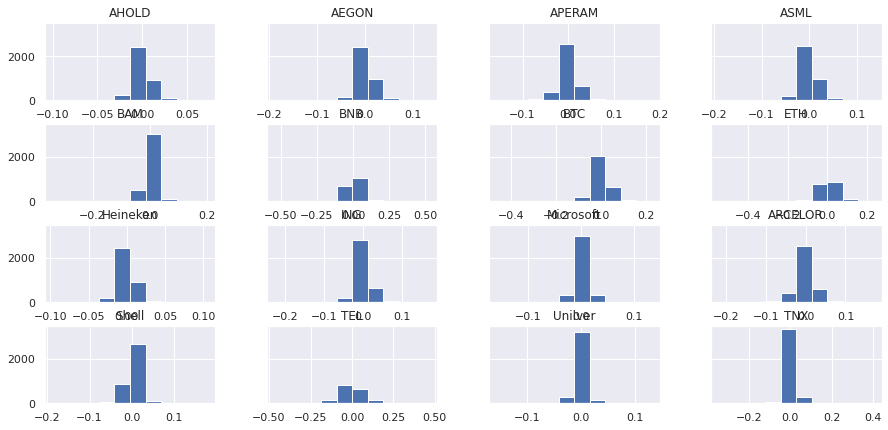

In [36]:
return_portfolio.hist(layout = (4, 4), figsize = (15, 7), sharey = True)

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7f54b95e0e80>,
      dtype=object)

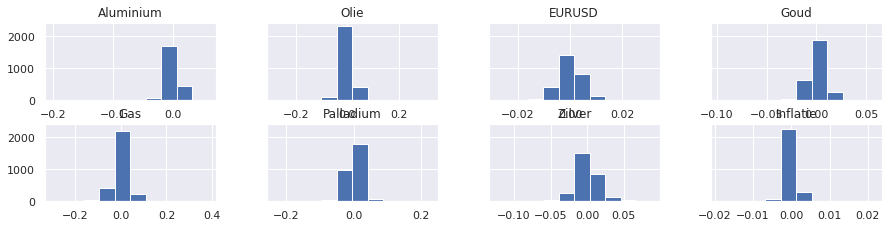

In [37]:
return_portfolio_eco.hist(layout = (4, 4), figsize = (15, 7), sharey = True)

In [38]:
return_portfolio.skew(axis = 0)

AHOLD       -0.430334
AEGON       -0.795293
APERAM       0.443904
ASML        -0.144823
BAM         -1.801660
BNB          0.374626
BTC         -0.774923
ETH         -0.907440
Heineken    -0.068764
ING         -0.767553
Microsoft   -0.227982
ARCELOR     -0.543914
Shell       -0.984075
TEL          0.484985
Unilver     -0.430907
TNX          0.335435
dtype: float64

In [39]:
return_portfolio.kurt(axis = 0)

AHOLD         7.893371
AEGON        11.768777
APERAM        6.881907
ASML          8.290461
BAM          29.218108
BNB          14.749845
BTC          10.834242
ETH           9.527067
Heineken      7.799902
ING          15.040238
Microsoft    13.205153
ARCELOR       8.852766
Shell        23.774696
TEL           4.499311
Unilver      25.703328
TNX          40.090416
dtype: float64

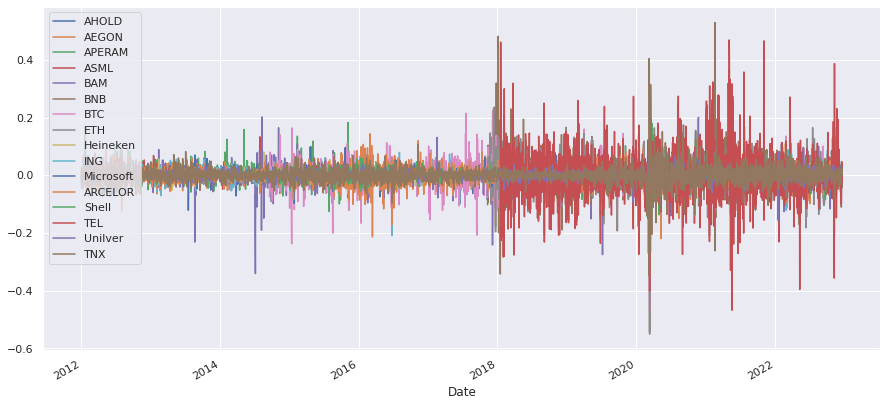

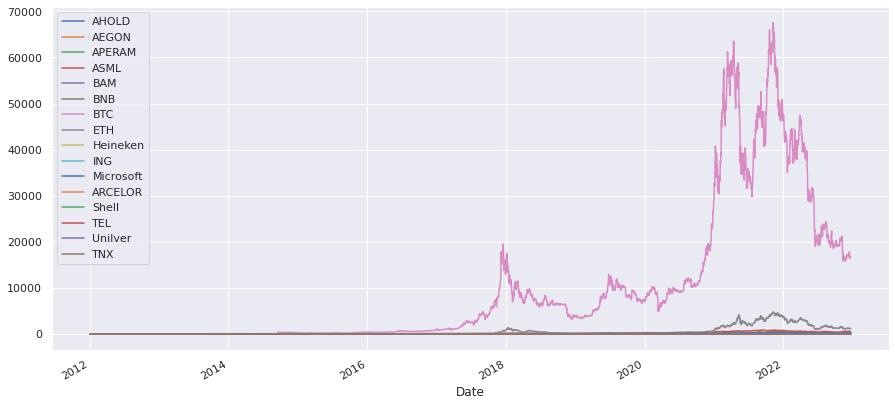

In [40]:
return_portfolio.plot(figsize = (15, 7))
#Plot van close onnutig inverband met uitschieters (Crypto's) ook met Y lim wordt het niet praktisch. Misschien opsplitsen?
filter_portfolio.plot(figsize = (15, 7))

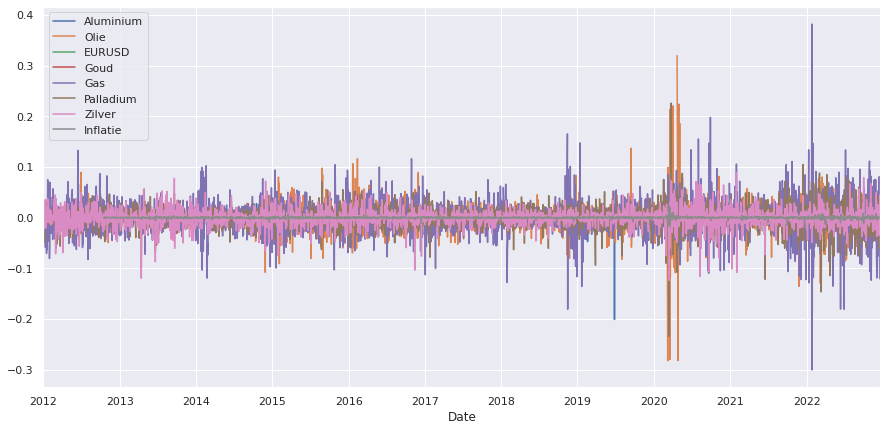

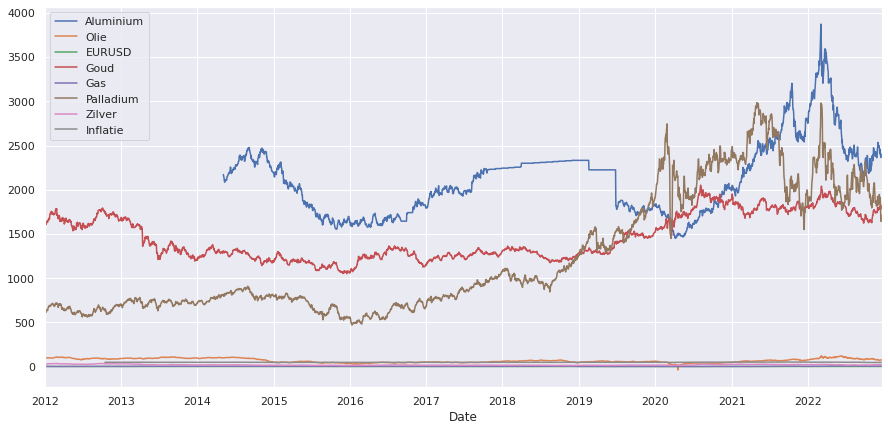

In [41]:
return_portfolio_eco.plot(figsize = (15, 7))
filter_portfolio_eco.plot(figsize = (15, 7))

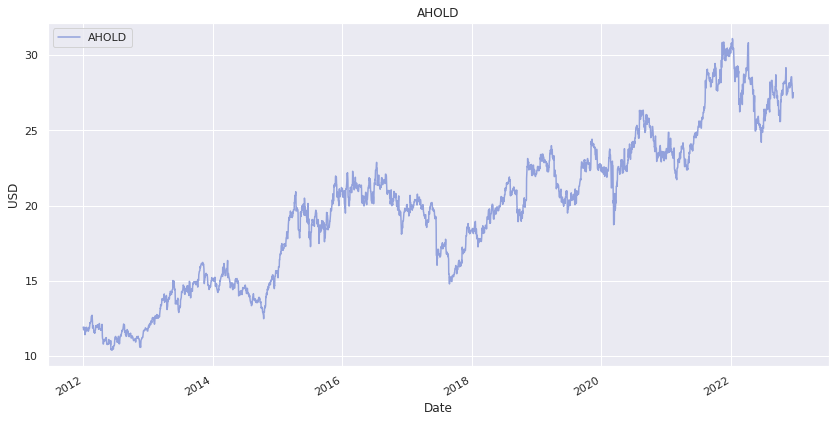

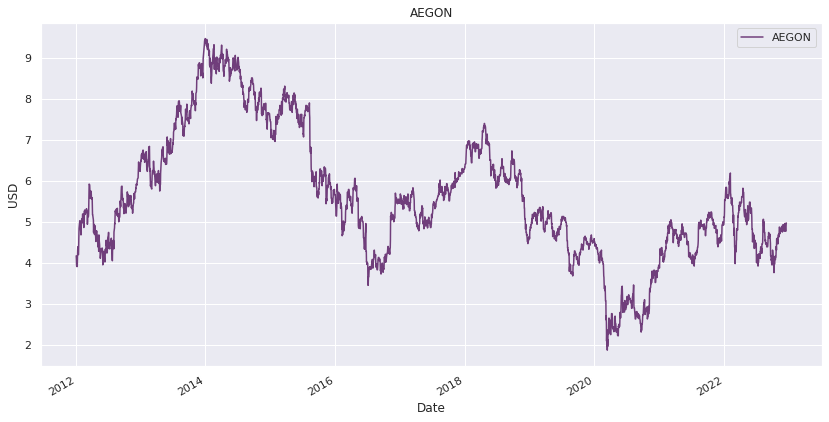

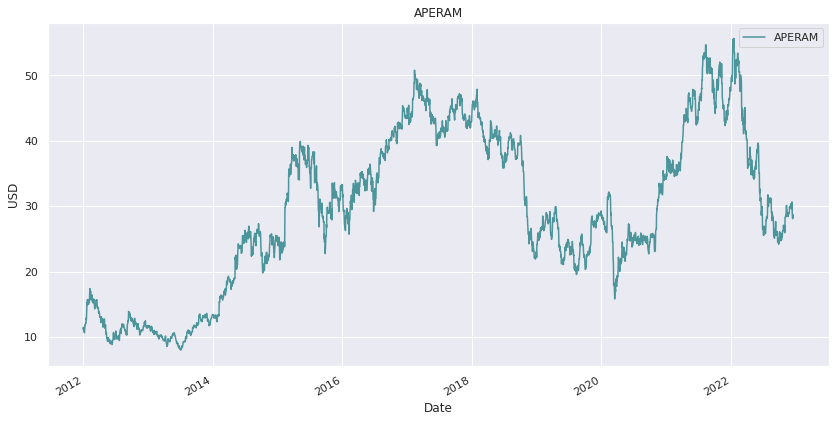

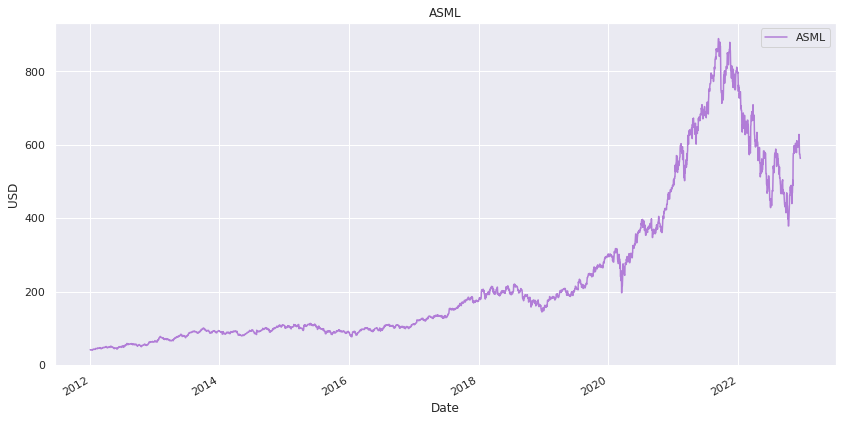

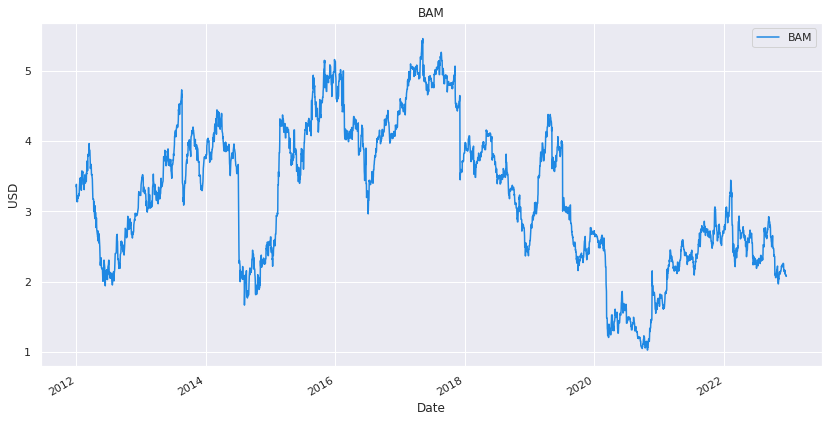

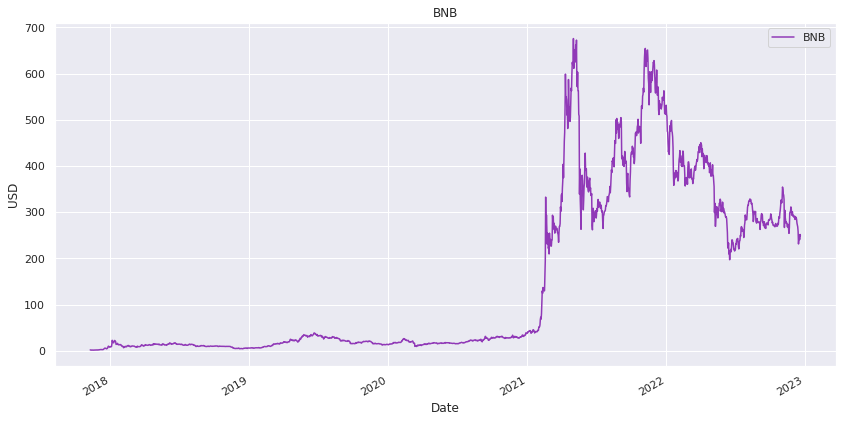

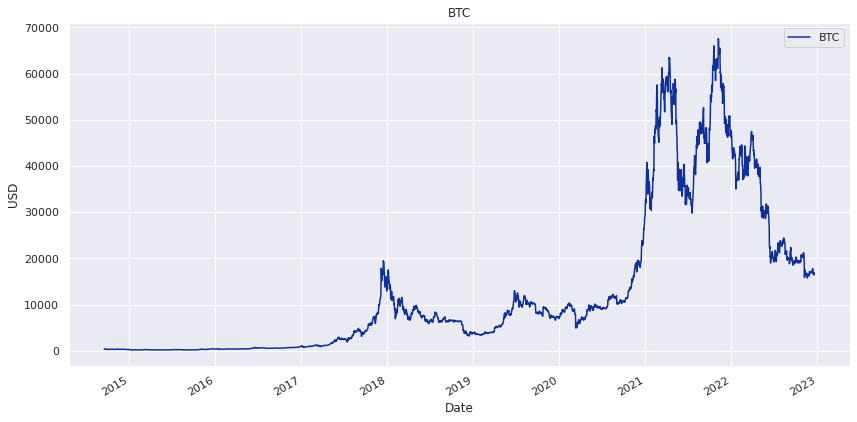

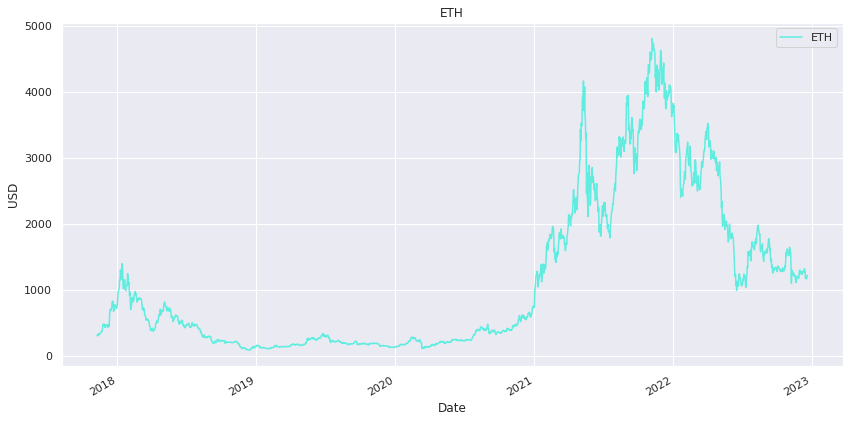

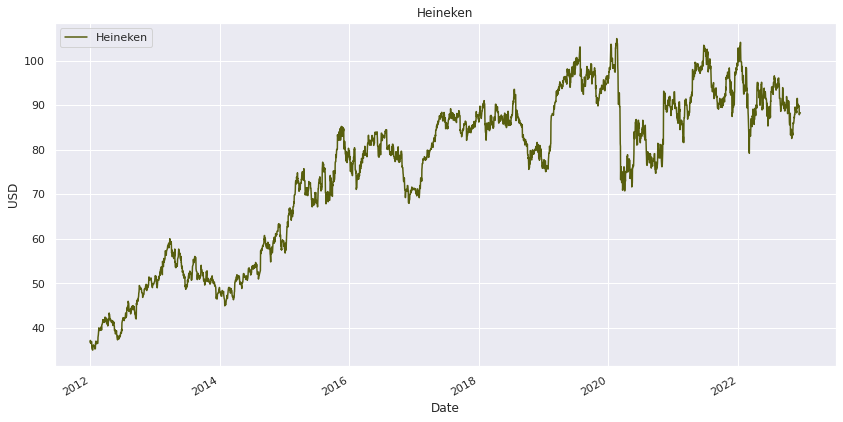

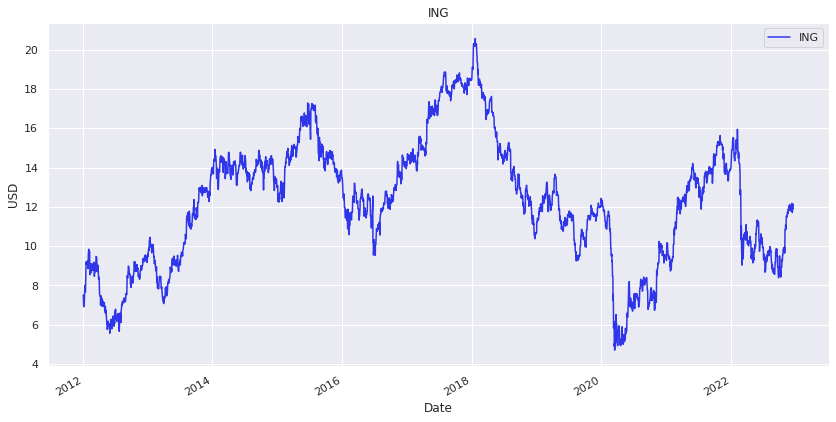

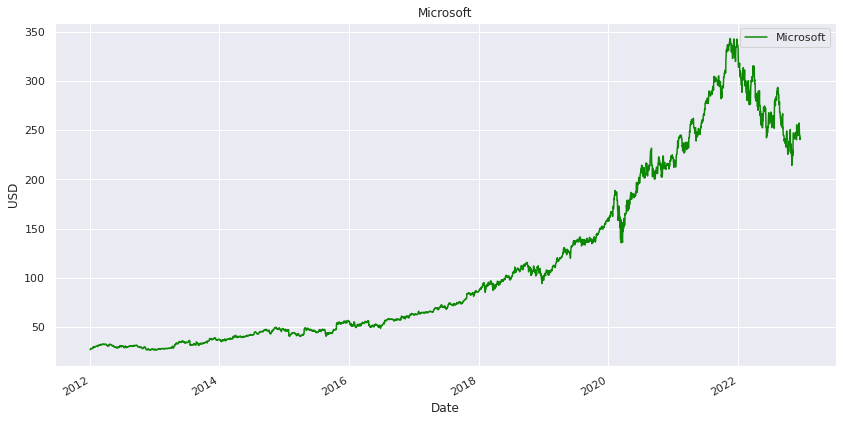

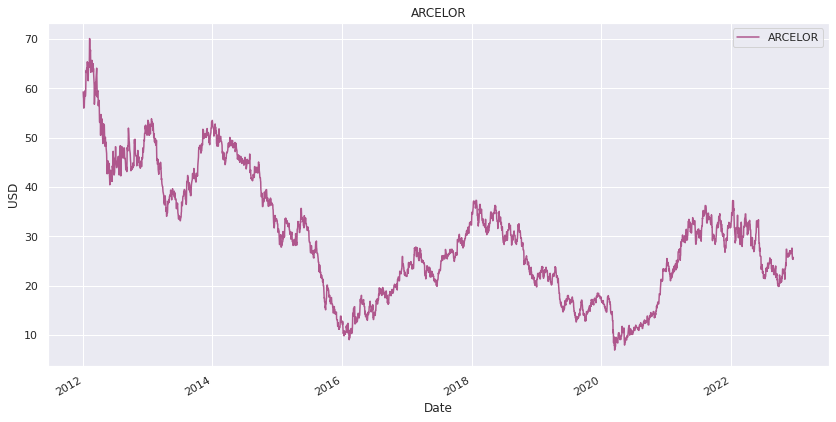

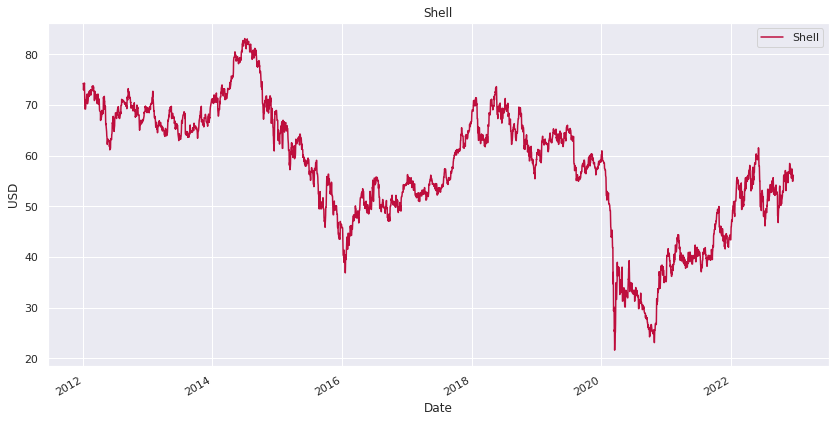

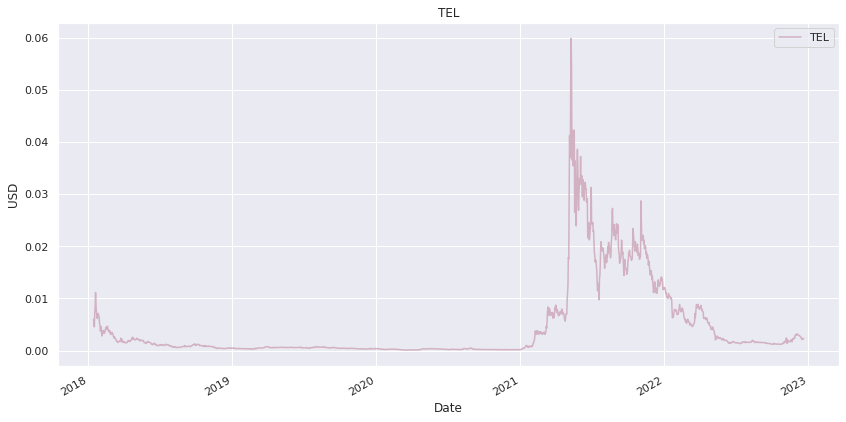

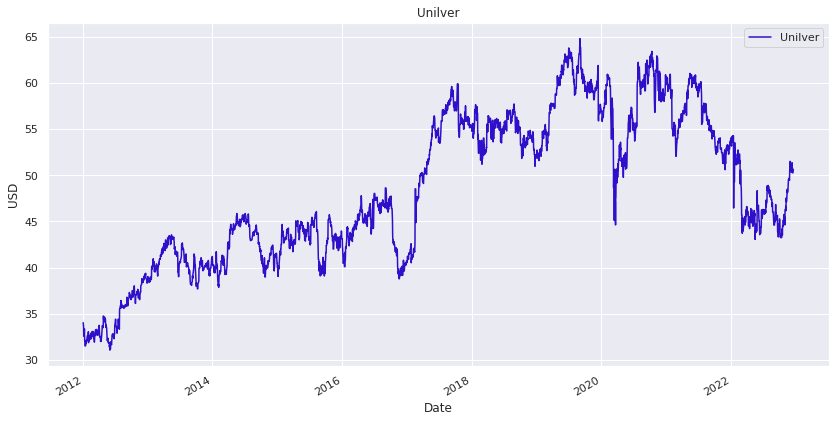

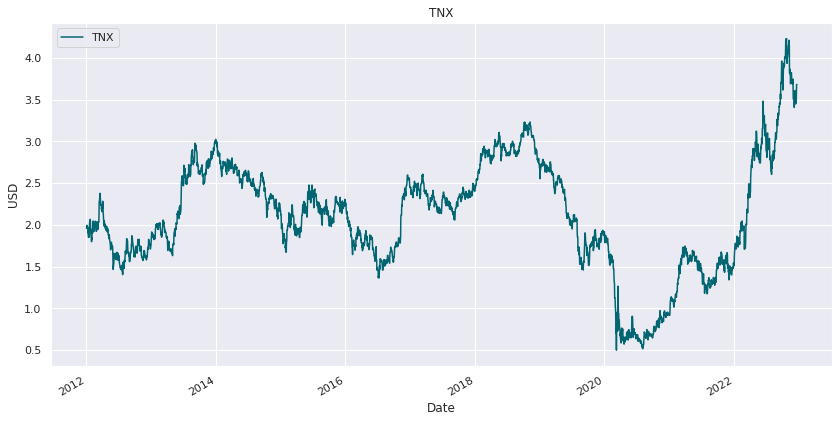

In [42]:
color = ["#"+''.join([random.choice('0123456789ABCDEF') for i in range(6)])
       for j in range(len(filter_portfolio.columns))]
for column in range(len(filter_portfolio.columns)):
  filter_portfolio.plot(kind = 'line',
                        y = filter_portfolio.columns[column],
                        color = color[column])
  plt.ylabel('USD') 
  plt.title(filter_portfolio.columns[column].lstrip('Close_'))

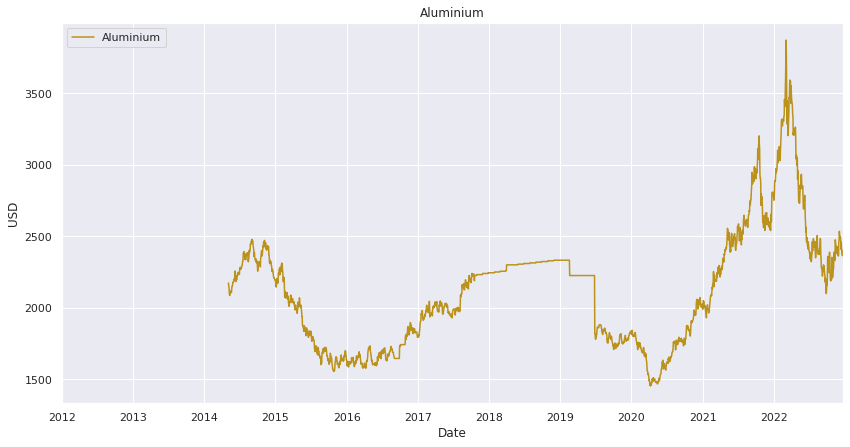

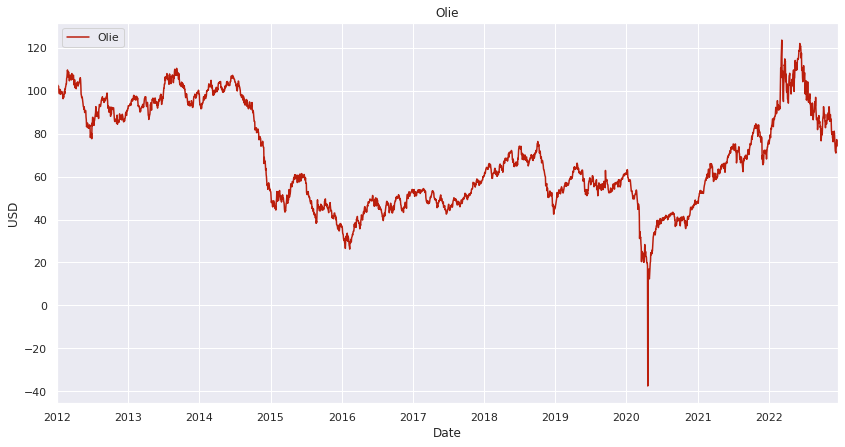

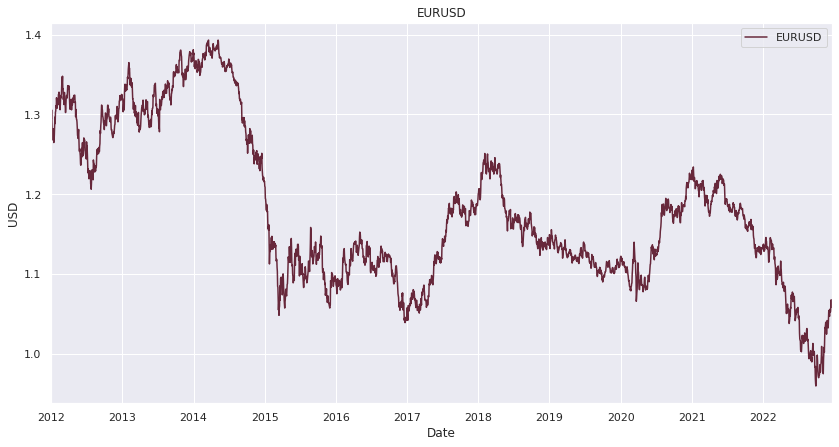

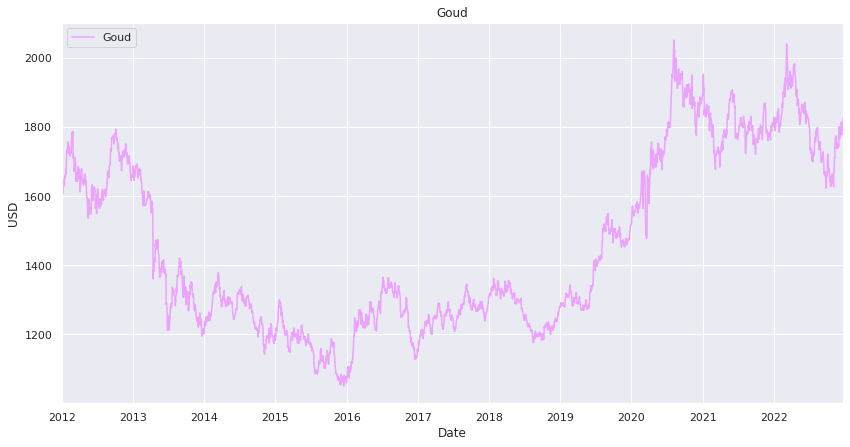

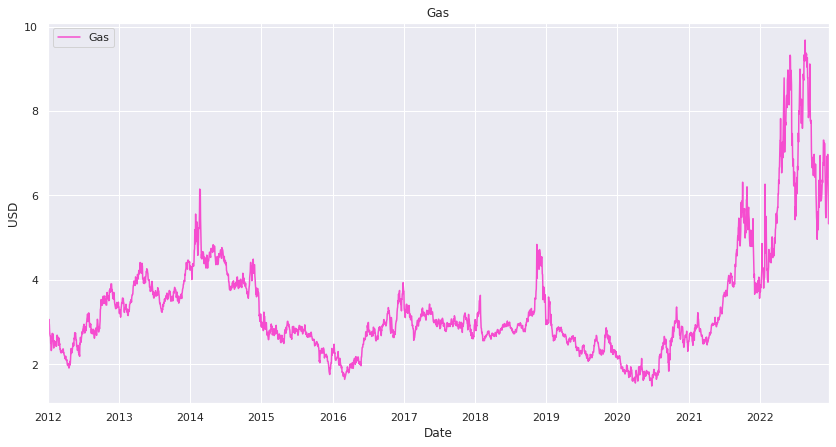

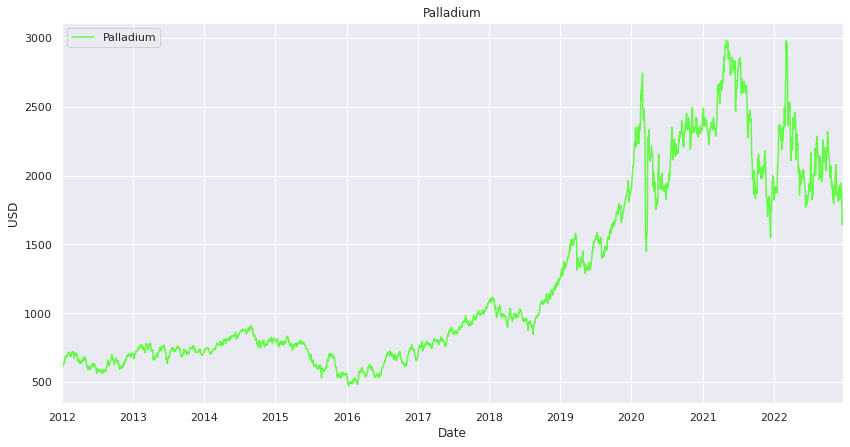

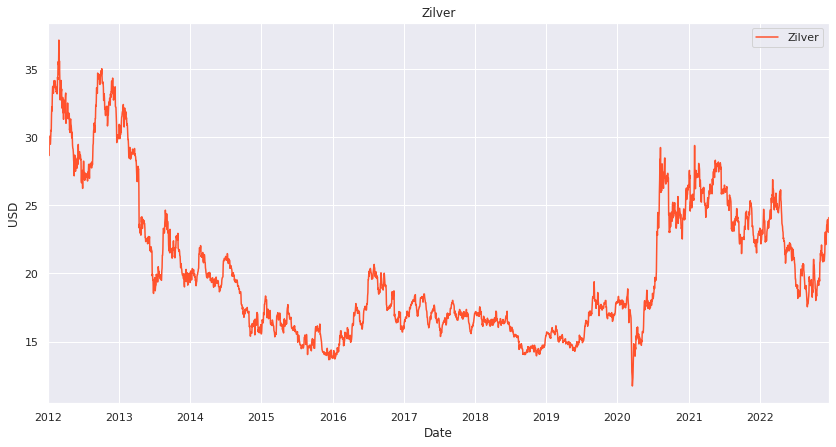

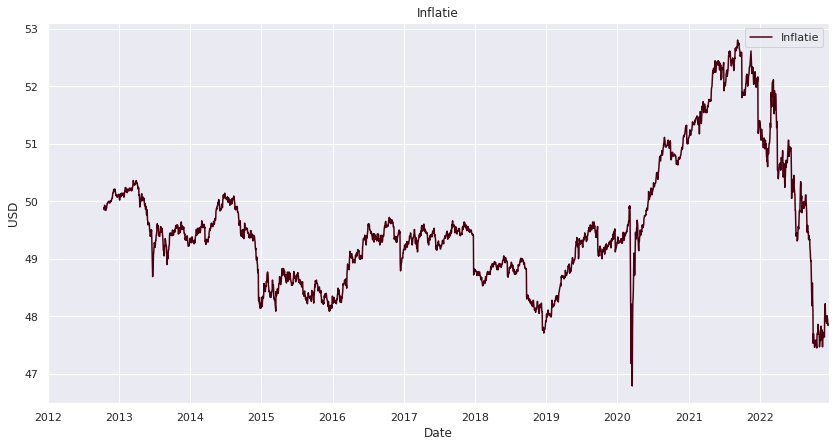

In [43]:
color = ["#"+''.join([random.choice('0123456789ABCDEF') for i in range(6)])
       for j in range(len(filter_portfolio_eco.columns))]
for column in range(len(filter_portfolio_eco.columns)):
  filter_portfolio_eco.plot(kind = 'line',
                        y = filter_portfolio_eco.columns[column],
                        color = color[column])
  plt.ylabel('USD') 
  plt.title(filter_portfolio_eco.columns[column].lstrip('Close_'))


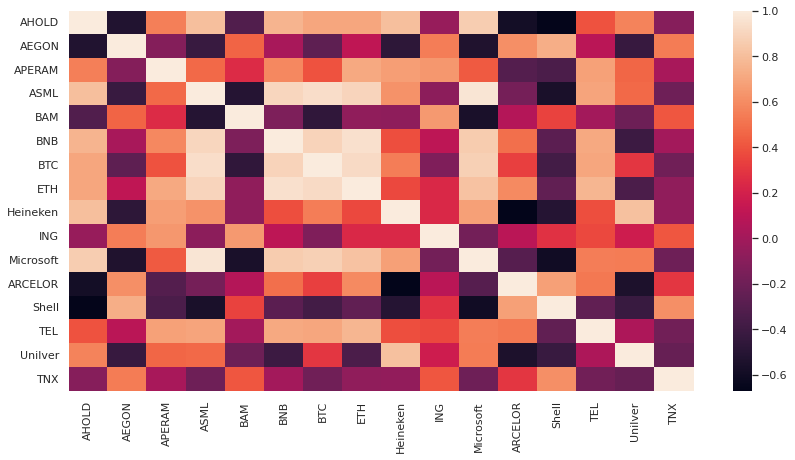

In [44]:
sns.heatmap(filter_portfolio.corr())

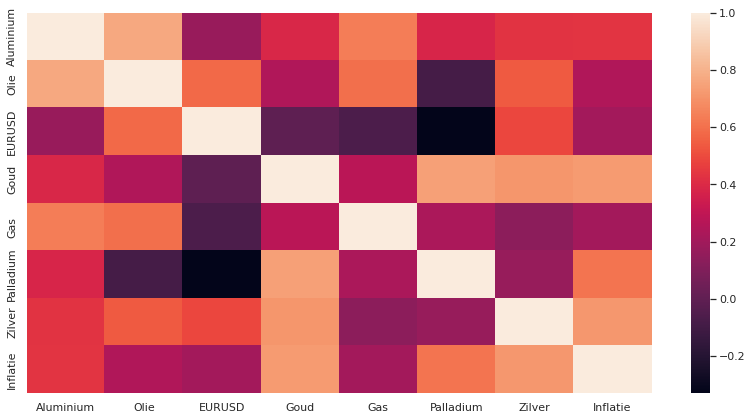

In [45]:
sns.heatmap(filter_portfolio_eco.corr())

In [46]:
meanReturns

AD.AS       0.000291
AEG         0.000250
APAM.AS     0.000489
ASML        0.000866
BAMNB.AS    0.000163
BNB-USD     0.004347
BTC-USD     0.001941
ETH-USD     0.002024
HEIA.AS     0.000303
ING         0.000332
MSFT        0.000697
MT          0.000105
SHEL        0.000056
TEL-USD     0.003122
UL          0.000173
^TNX        0.000520
dtype: float64

In [47]:
meanReturns_eco

ALI=F       0.000113
CL=F       -0.001035
EURUSD=X   -0.000057
GC=F        0.000093
NG=F        0.000803
PA=F        0.000550
SI=F        0.000089
VTIP       -0.000014
dtype: float64

In [48]:
covMatrix

,AD.AS,AEG,APAM.AS,ASML,BAMNB.AS,BNB-USD,BTC-USD,ETH-USD,HEIA.AS,ING,MSFT,MT,SHEL,TEL-USD,UL,^TNX
AD.AS,0.000132,0.000046,0.000056,0.000027,0.000050,0.000024,0.000006,0.000017,0.000038,0.000045,0.000025,0.000039,0.000026,0.000019,0.000032,0.000034
AEG,0.000046,0.000403,0.000190,0.000147,0.000199,0.000186,0.000083,0.000188,0.000063,0.000302,0.000099,0.000301,0.000174,0.000232,0.000068,0.000208
APAM.AS,0.000056,0.000190,0.000477,0.000129,0.000210,0.000162,0.000090,0.000171,0.000065,0.000209,0.000071,0.000320,0.000134,0.000169,0.000047,0.000140
ASML,0.000027,0.000147,0.000129,0.000338,0.000100,0.000245,0.000133,0.000277,0.000042,0.000158,0.000150,0.000221,0.000117,0.000317,0.000072,0.000066
BAMNB.AS,0.000050,0.000199,0.000210,0.000100,0.000570,0.000184,0.000075,0.000190,0.000068,0.000214,0.000059,0.000216,0.000132,0.000202,0.000041,0.000149
BNB-USD,0.000024,0.000186,0.000162,0.000245,0.000184,0.003689,0.001532,0.001908,0.000045,0.000182,0.000190,0.000284,0.000164,0.002035,0.000078,0.000010
BTC-USD,0.000006,0.000083,0.000090,0.000133,0.000075,0.001532,0.001474,0.001569,0.000016,0.000094,0.000098,0.000144,0.000087,0.001706,0.000041,0.000012
ETH-USD,0.000017,0.000188,0.000171,0.000277,0.000190,0.001908,0.001569,0.002577,0.000047,0.000198,0.000209,0.000281,0.000176,0.002317,0.000084,0.000019
HEIA.AS,0.000038,0.000063,0.000065,0.000042,0.000068,0.000045,0.000016,0.000047,0.000133,0.000063,0.000034,0.000053,0.000041,0.000070,0.000051,0.000041
ING,0.000045,0.000302,0.000209,0.000158,0.000214,0.000182,0.000094,0.000198,0.000063,0.000404,0.000107,0.000311,0.000181,0.000249,0.000079,0.000208


In [49]:
covMatrix_eco

,ALI=F,CL=F,EURUSD=X,GC=F,NG=F,PA=F,SI=F,VTIP
ALI=F,0.000136,0.000086,3.801277e-06,1.156298e-05,2.476550e-05,0.000054,0.000036,1.433322e-06
CL=F,0.000086,0.004579,-3.565875e-06,3.010870e-05,2.169831e-05,0.000176,0.000090,1.773385e-05
EURUSD=X,0.000004,-0.000004,2.573762e-05,2.731552e-06,6.296250e-06,0.000005,0.000003,2.499051e-08
GC=F,0.000012,0.000030,2.731552e-06,9.452418e-05,6.215795e-07,0.000075,0.000140,3.545882e-06
NG=F,0.000025,0.000022,6.296250e-06,6.215795e-07,1.191350e-03,0.000034,0.000017,4.055757e-06
PA=F,0.000054,0.000176,5.217331e-06,7.453363e-05,3.386249e-05,0.000442,0.000162,4.522190e-06
SI=F,0.000036,0.000090,3.248472e-06,1.403283e-04,1.662419e-05,0.000162,0.000319,5.589738e-06
VTIP,0.000001,0.000018,2.499051e-08,3.545882e-06,4.055757e-06,0.000005,0.000006,3.256953e-06


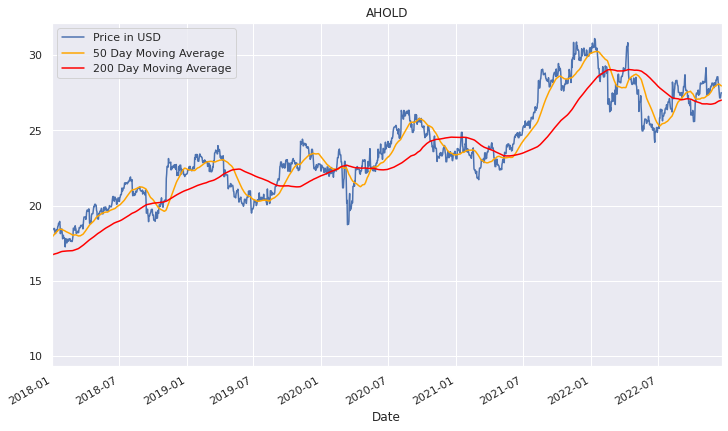

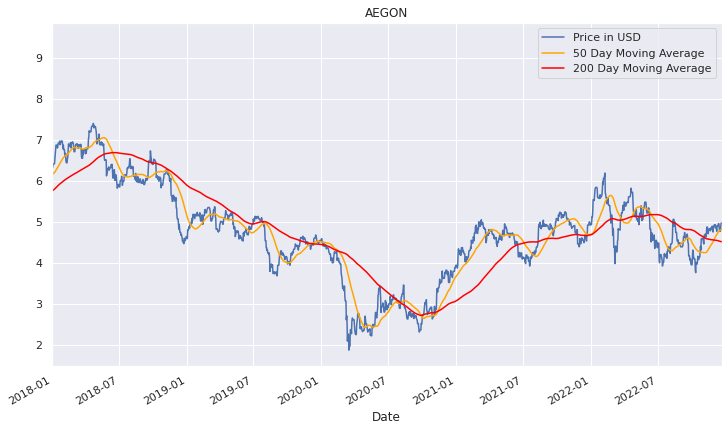

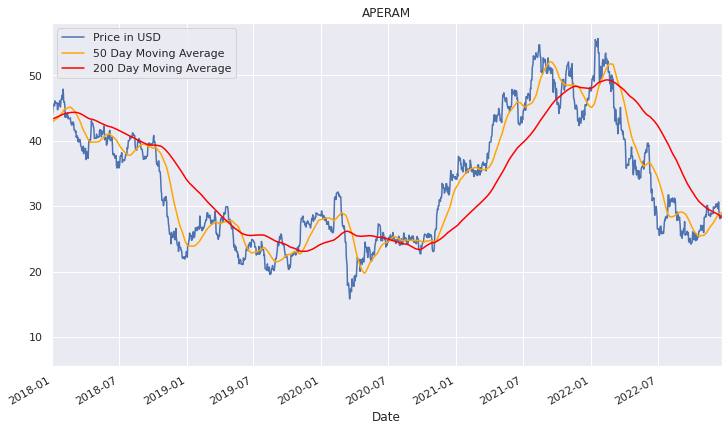

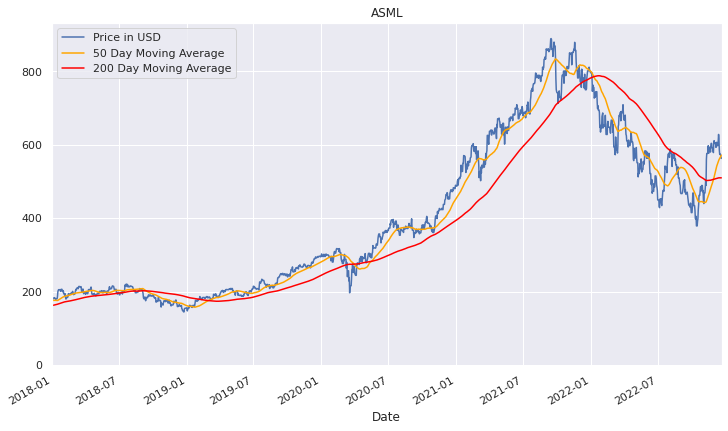

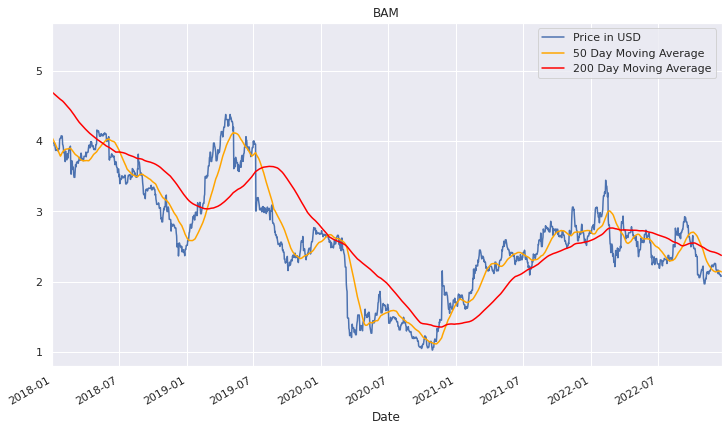

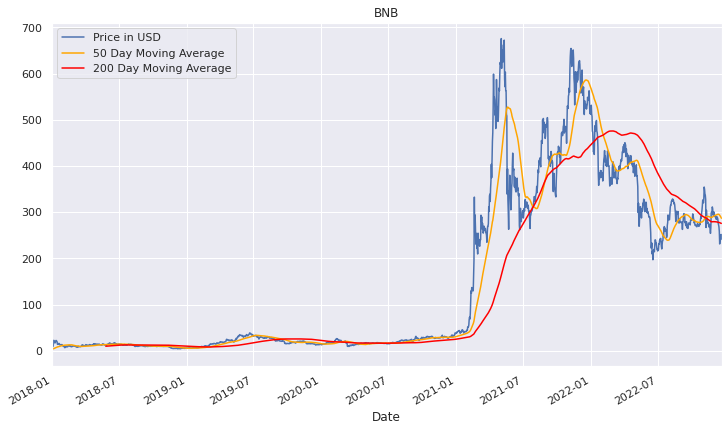

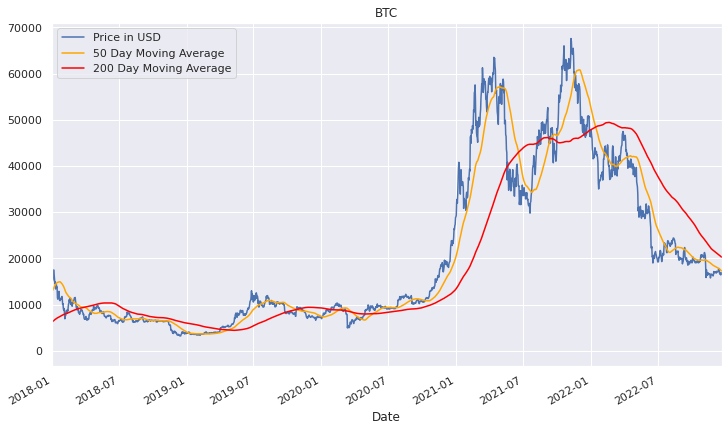

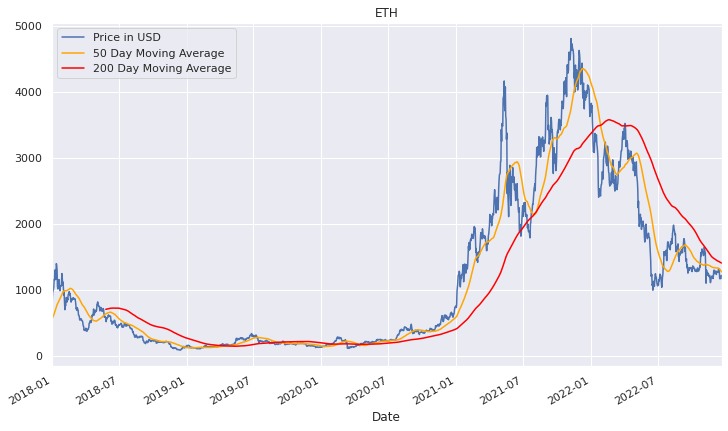

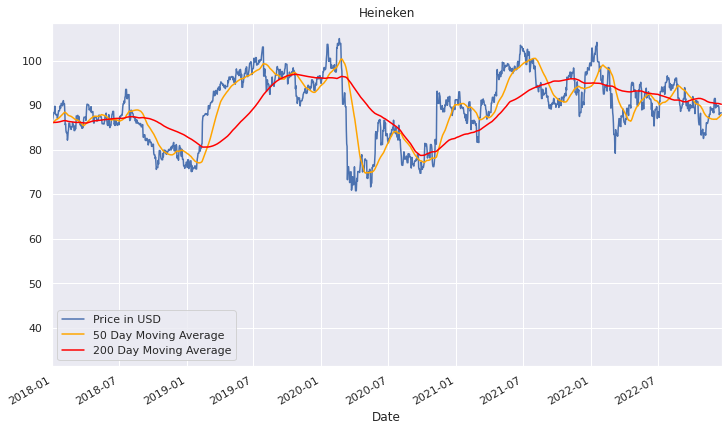

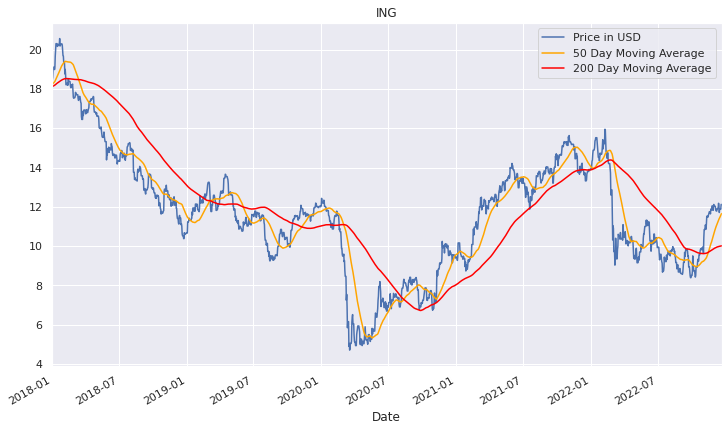

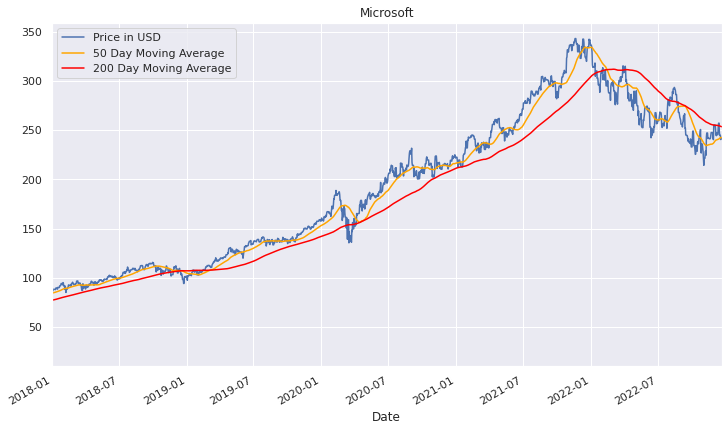

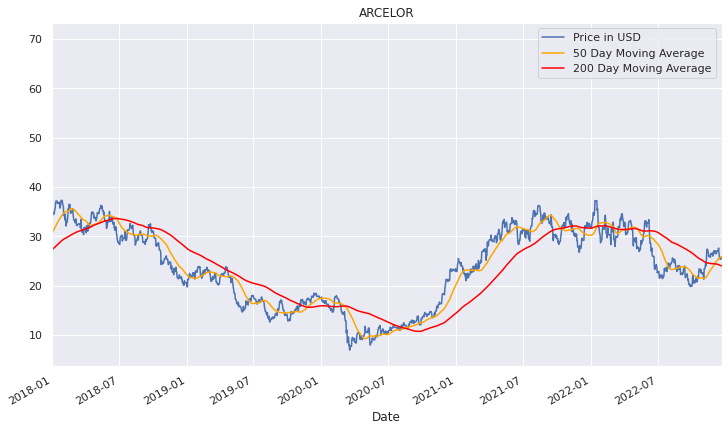

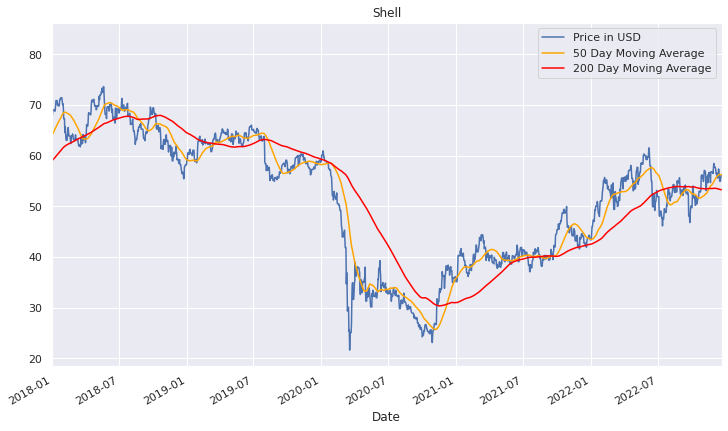

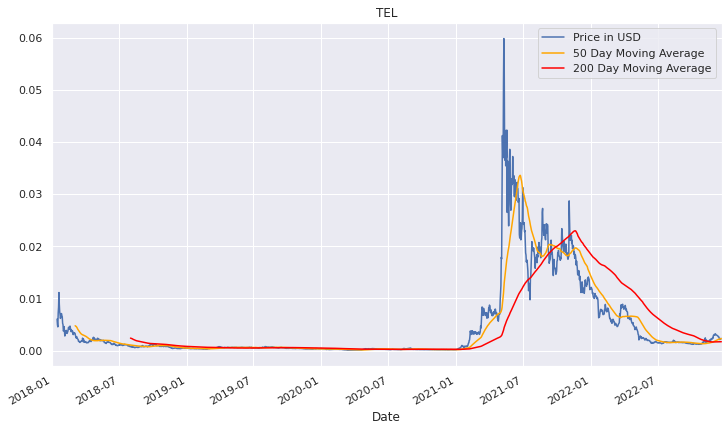

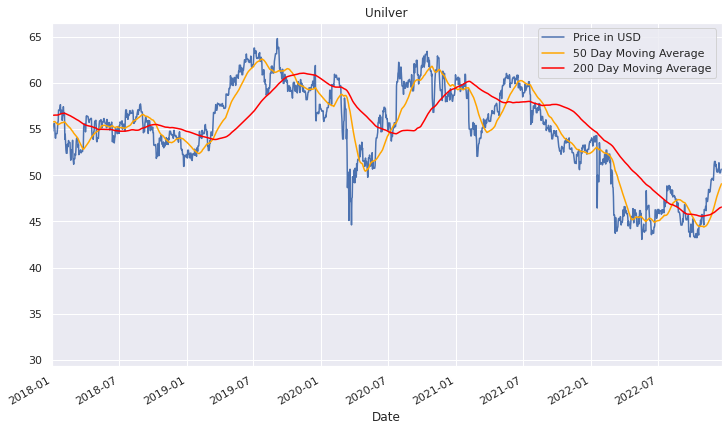

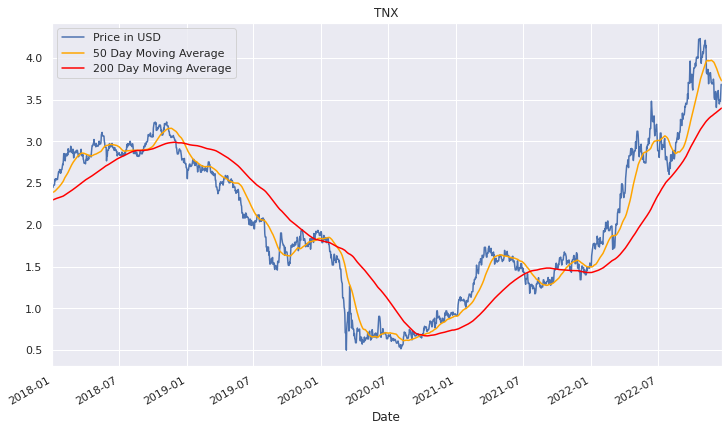

In [50]:
graphs = filter_portfolio

for index in range(len(filter_portfolio.columns)):
  graphs[graphs.columns[index]].plot(figsize = (12,7), label='Price in USD')


  graphs['50 Day Moving Average'] = graphs[graphs.columns[index]].rolling(50).mean()
  graphs['50 Day Moving Average'].plot(color="orange")


  graphs['200 Day Moving Average'] = graphs[graphs.columns[index]].rolling(200).mean()
  graphs['200 Day Moving Average'].plot(color="red")


  plt.xlim(dt.date(2018, 1, 1), date.today())
  plt.title(graphs.columns[index])
  plt.legend()
  plt.show()
  graphs.drop('50 Day Moving Average', inplace = True, axis = 1)
  graphs.drop('200 Day Moving Average', inplace = True, axis = 1)



# Meervoudige lineaire regressie

In [51]:
return_portfolio_final = pd.merge(return_portfolio_eco, return_portfolio,
                how = 'left', on = 'Date')
return_portfolio_final = return_portfolio_final.dropna()

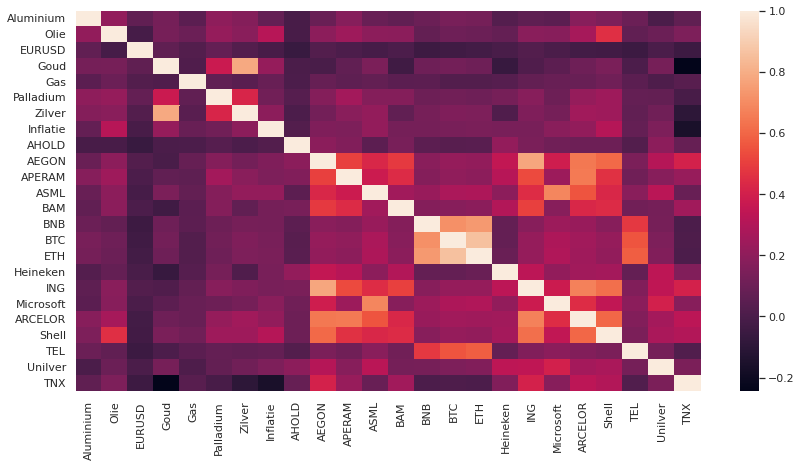

In [52]:
sns.heatmap(return_portfolio_final.corr())

voor alle aandelen word er een Rsquared berekend met alle voorspellende variabelen (dus ook ander aandelen) en Durbin Watson test uitgevoerd. Hetzelfde wordt nogmaals gedaan met een constante toegevoegd. Hieruit blijkt dat een constante de R-squared verbeterd dus deze zullen we meenemen in ons model.

In [53]:
aandeel = []
rsquared = []
rsquared_c = []
DW = []
DW_c = []

for col in range(len(return_portfolio.columns)):
  aandeel.append(return_portfolio_final.columns[len(return_portfolio_eco.columns) + col])
  X = return_portfolio_final.drop(return_portfolio_final.columns[len(return_portfolio_eco.columns) + col], axis = 1)
  y = return_portfolio_final[return_portfolio_final.columns[len(return_portfolio_eco.columns) + col]]
  reg = sm.OLS(y, X).fit()
  rsquared.append(reg.rsquared)
  DW.append(dwtest(resids=np.array(reg.resid)))
  X = sm.add_constant(X)
  reg = sm.OLS(y, X).fit()
  rsquared_c.append(reg.rsquared)
  DW_c.append(dwtest(resids=np.array(reg.resid)))




df = pd.DataFrame(list(zip(aandeel, rsquared, DW, rsquared_c, DW_c)),
                  columns = ["Aandeel", 'R-squared', 'DW-Test', 'R-squared + c', 'DW-Test + c'])
df

,Aandeel,R-squared,DW-Test,R-squared + c,DW-Test + c
0,AHOLD,0.100601,2.022336,0.100701,2.023515
1,AEGON,0.672540,2.153616,0.672525,2.153634
2,APERAM,0.508772,2.195725,0.508730,2.196115
3,ASML,0.580809,2.108561,0.580629,2.110921
4,BAM,0.353163,2.048762,0.353047,2.048925
5,BNB,0.580326,1.873318,0.581175,1.878731
6,BTC,0.760211,1.952491,0.760266,1.952996
7,ETH,0.784242,1.916973,0.784795,1.922331
8,Heineken,0.256055,2.105593,0.256128,2.105787
9,ING,0.701064,1.901238,0.701015,1.901257


Onderstaand worden voor alle koersen een de koers voorspeld aan de hand van historische data. Dit gebeurd alleen als de R-squared hoger is dan een bepaalde waarde. In dit geval staat 0.5 ingesteld.

In [54]:
portfolio_prediction = pd.DataFrame()

for col in range(len(return_portfolio.columns)):
  Xdrop = []
  X = return_portfolio_final.drop(return_portfolio_final.columns[len(return_portfolio_eco.columns) + col], axis = 1)
  y = return_portfolio_final[return_portfolio_final.columns[len(return_portfolio_eco.columns) + col]]
  X = sm.add_constant(X)
  
  reg = sm.OLS(y, X).fit()

  for i in range(len(X.columns)):
    if reg.pvalues[i] > 0.05:
      Xdrop.append(X.columns[i])

  X = X.drop(Xdrop, axis = 1)
  reg = sm.OLS(y, X).fit()

  if reg.rsquared > 0.5:
    name = return_portfolio_final[return_portfolio_final.columns[len(return_portfolio_eco.columns) + col]]
    portfolio_prediction[return_portfolio_final.columns[len(return_portfolio_eco.columns) + col]] = name
    portfolio_prediction['Voorspelde waarde ' + return_portfolio_final.columns[len(return_portfolio_eco.columns) + col]] = reg.predict(X)

Voorbeeld van de daadwerkelijke verandering van de koers en de voorspelde waarde hiervan.

In [55]:
# portfolio_prediction[['BTC', 'Voorspelde waarde BTC']]
portfolio_prediction

,AEGON,Voorspelde waarde AEGON,APERAM,Voorspelde waarde APERAM,ASML,Voorspelde waarde ASML,BNB,Voorspelde waarde BNB,BTC,Voorspelde waarde BTC,ETH,Voorspelde waarde ETH,ING,Voorspelde waarde ING,Microsoft,Voorspelde waarde Microsoft,ARCELOR,Voorspelde waarde ARCELOR,Shell,Voorspelde waarde Shell
Date,,,,,,,,,,,,,,,,,,,,
2018-01-16,-0.010227,-0.006662,-0.022969,-0.001232,0.030009,-0.016552,-0.342421,-0.186826,-0.184582,-0.157740,-0.203831,-0.235260,-0.006917,-0.008211,-0.014049,0.017658,-0.012184,-0.010003,-0.012779,-0.004568
2018-01-17,0.007315,0.004554,0.000223,0.005230,0.066421,0.012863,0.022161,-0.033356,-0.026625,-0.020847,-0.038149,-0.022634,0.003958,0.005629,0.020058,0.034241,-0.000818,0.019159,0.003139,0.006339
2018-01-18,0.010152,0.000411,0.016833,0.001471,0.020769,-0.000528,0.005421,0.038126,0.025267,0.027976,0.021488,0.054918,-0.001483,0.005863,-0.000444,0.009731,-0.000818,0.011101,-0.002282,0.002746
2018-01-19,0.000000,0.004832,0.003508,0.006902,0.010566,-0.001411,0.045194,0.011421,0.011481,0.011782,0.002718,0.029391,0.002470,0.005368,-0.001110,0.010632,0.005985,0.003922,-0.003003,-0.000549
2018-01-22,0.007189,0.013833,0.008933,0.003386,0.000097,0.014447,-0.077852,-0.053697,-0.059374,-0.039519,-0.045135,-0.076608,0.014692,0.010700,0.017731,-0.000001,0.001897,0.013571,0.017179,0.007311
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-15,-0.018424,-0.021995,-0.021781,-0.021443,-0.049120,-0.029680,-0.037831,-0.031092,-0.025628,-0.025915,-0.033373,-0.035771,-0.025296,-0.016305,-0.032439,-0.025724,-0.026262,-0.039556,-0.010805,-0.017971
2022-12-16,-0.012474,0.002354,-0.017631,-0.010163,-0.020713,-0.020140,-0.110596,-0.061735,-0.042190,-0.060031,-0.080627,-0.064371,0.016095,-0.012857,-0.017501,-0.011418,-0.018292,-0.016042,-0.021421,-0.008312
2022-12-19,0.024795,0.001362,0.003906,-0.002155,-0.009992,-0.015262,-0.042700,-0.013743,-0.019176,-0.011478,-0.014544,-0.021329,-0.001682,0.013743,-0.017480,-0.002881,-0.004330,0.002925,0.010138,0.003822


AEGON
Voorspelde waarde AEGON


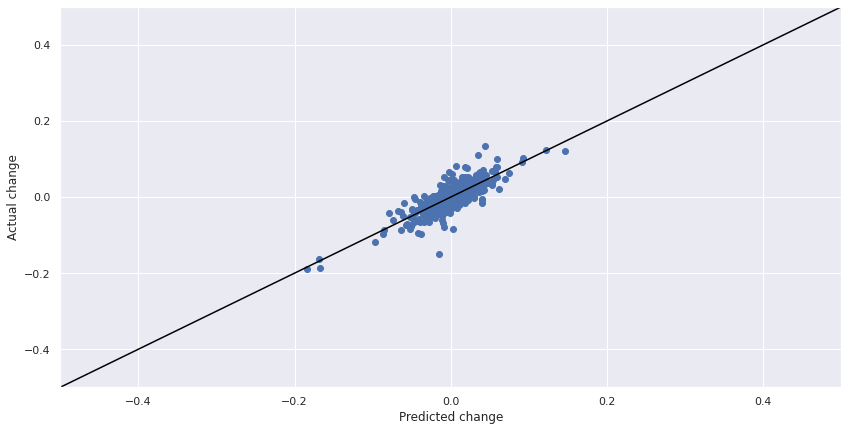

APERAM
Voorspelde waarde APERAM


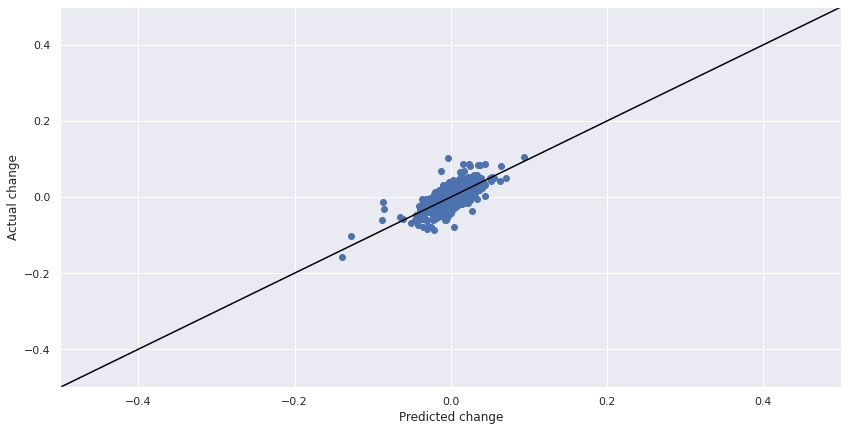

ASML
Voorspelde waarde ASML


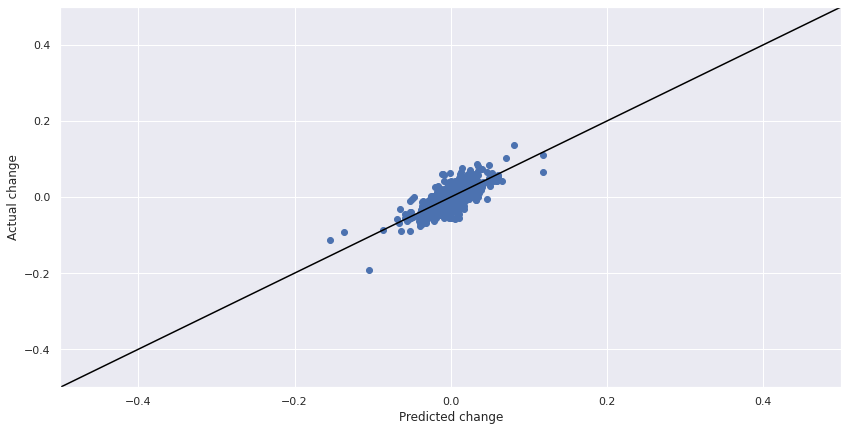

BNB
Voorspelde waarde BNB


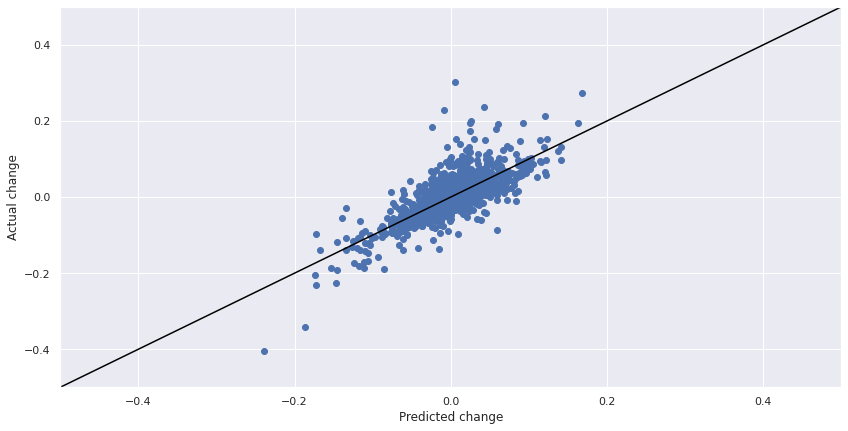

BTC
Voorspelde waarde BTC


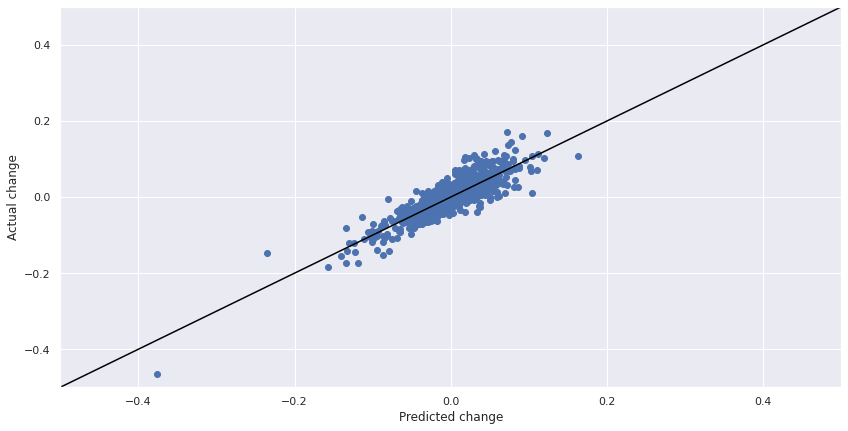

ETH
Voorspelde waarde ETH


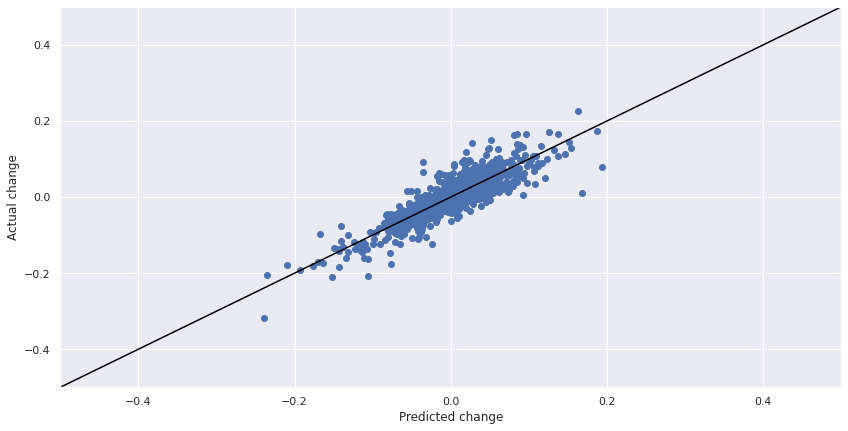

ING
Voorspelde waarde ING


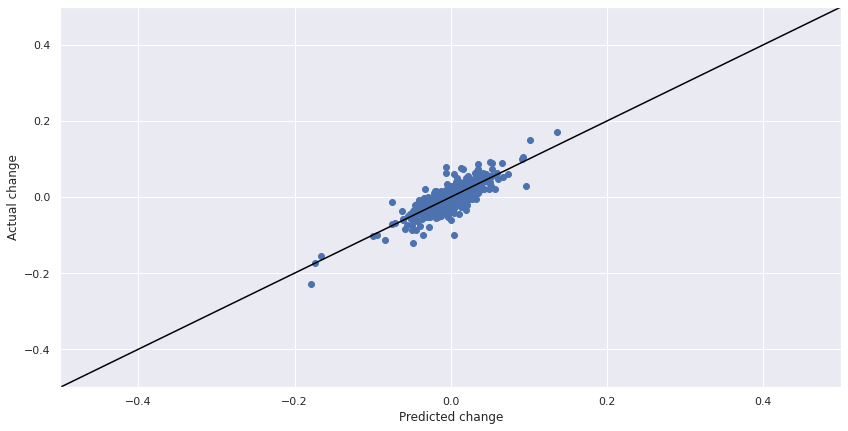

Microsoft
Voorspelde waarde Microsoft


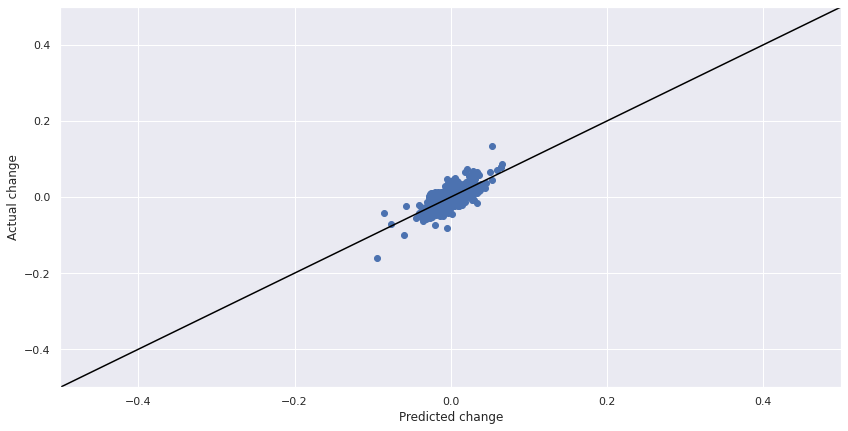

ARCELOR
Voorspelde waarde ARCELOR


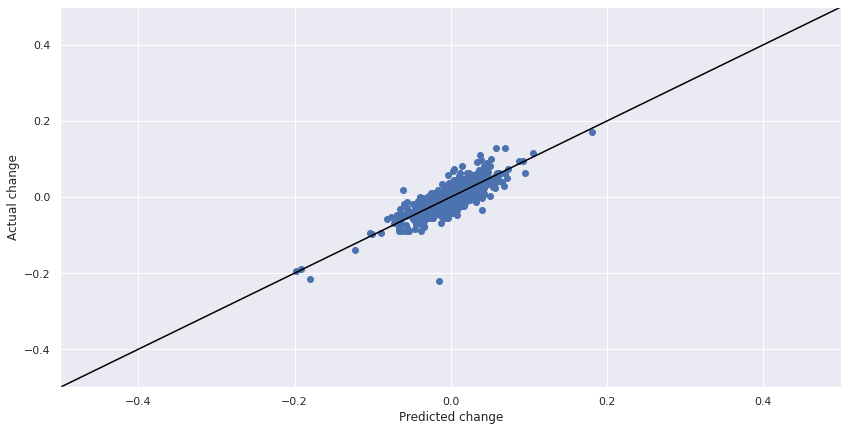

Shell
Voorspelde waarde Shell


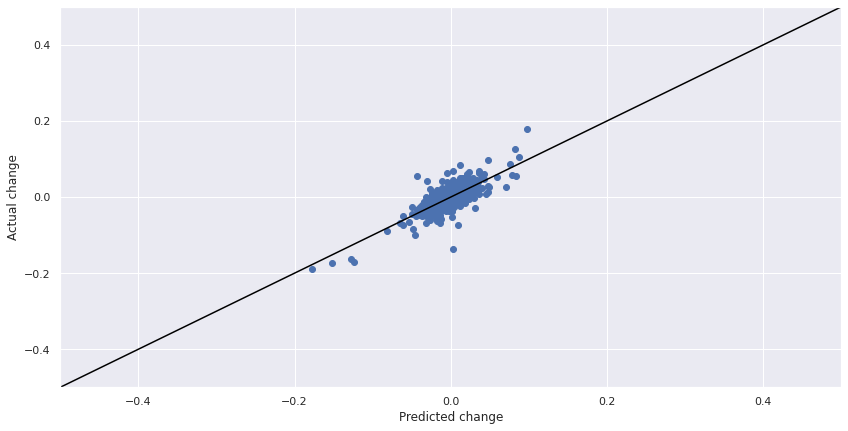

In [56]:

for share in range(int(len(portfolio_prediction.columns)/2)):
  plt.scatter(portfolio_prediction.iloc[:, 1 + share*2], portfolio_prediction.iloc[:, share*2])
  print(portfolio_prediction.columns[share*2])
  print(portfolio_prediction.columns[1 + share*2])
  plt.xlim(-0.5, 0.5)
  plt.ylim(-0.5, 0.5)
  plt.ylabel('Actual change')
  plt.xlabel('Predicted change')
  plt.plot([-0.5, 0.5], [-0.5, 0.5], 'black') #1 to 1 line
  plt.show()


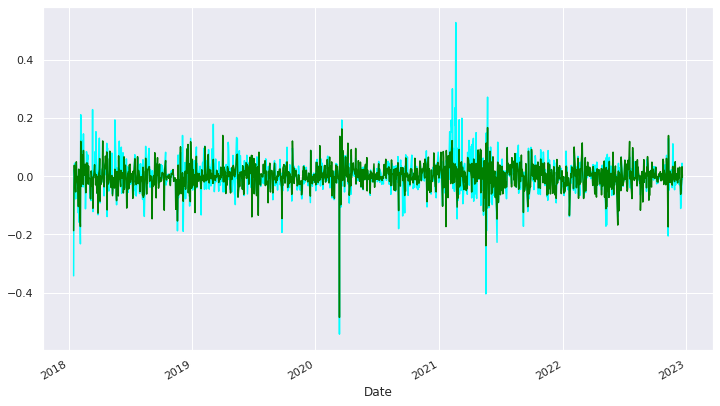

In [57]:
portfolio_prediction['BNB'].plot(figsize = (12,7), label='Price in USD', color = "cyan")
portfolio_prediction['Voorspelde waarde BNB'].plot(color="green", label='Regression')

In [58]:
misc = portfolio_prediction.pct_change(axis = 'columns', periods = 1).abs().replace(np.inf, 0)

for pred in range(int(len(misc.columns)/2)):
  miscalc = sum(misc.iloc[:, 1 + pred*2]) / len(misc)
  print(f'miscalculatie {misc.columns[pred*2]} is gemiddeld {round(miscalc, 2)} %')

misc


miscalculatie AEGON is gemiddeld nan %
miscalculatie APERAM is gemiddeld nan %
miscalculatie ASML is gemiddeld nan %
miscalculatie BNB is gemiddeld 5.5 %
miscalculatie BTC is gemiddeld 2.48 %
miscalculatie ETH is gemiddeld 2.69 %
miscalculatie ING is gemiddeld nan %
miscalculatie Microsoft is gemiddeld nan %
miscalculatie ARCELOR is gemiddeld nan %
miscalculatie Shell is gemiddeld nan %


,AEGON,Voorspelde waarde AEGON,APERAM,Voorspelde waarde APERAM,ASML,Voorspelde waarde ASML,BNB,Voorspelde waarde BNB,BTC,Voorspelde waarde BTC,ETH,Voorspelde waarde ETH,ING,Voorspelde waarde ING,Microsoft,Voorspelde waarde Microsoft,ARCELOR,Voorspelde waarde ARCELOR,Shell,Voorspelde waarde Shell
Date,,,,,,,,,,,,,,,,,,,,
2018-01-16,NaN,0.348605,2.448044,0.946382,25.366482,1.551576,19.687210,0.454397,0.012011,0.145419,0.292197,0.154192,0.970599,0.187127,0.710939,2.256852,1.689997,0.178956,0.277442,0.642510
2018-01-17,NaN,0.377435,0.950939,22.409197,11.698912,0.806346,0.722916,2.505156,0.201794,0.217023,0.829948,0.406688,1.174888,0.422089,2.563144,0.707118,1.023875,24.435706,0.836175,1.019578
2018-01-18,NaN,0.959471,39.910173,0.912606,13.117866,1.025417,11.268590,6.033510,0.337290,0.107217,0.231907,1.555771,1.026997,4.954394,1.075708,22.924103,1.084078,14.568219,1.205538,2.203601
2018-01-19,NaN,0.000000,0.273946,0.967474,0.530819,1.133579,33.022474,0.747299,0.005263,0.026254,0.769353,9.815287,0.915967,1.173522,1.206863,10.574297,0.437106,0.344689,1.765653,0.817284
2018-01-22,NaN,0.924162,0.354192,0.620925,0.971281,147.542005,6.388971,0.310271,0.105728,0.334404,0.142109,0.697298,1.191777,0.271689,0.657061,1.000062,1729.983947,6.154906,0.265879,0.574417
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-15,NaN,0.193813,0.009718,0.015547,1.290750,0.395755,0.274601,0.178125,0.175726,0.011201,0.287757,0.071864,0.292823,0.355450,0.989514,0.206982,0.020904,0.506193,0.726840,0.663226
2022-12-16,NaN,1.188735,8.488767,0.423573,1.038106,0.027656,4.491305,0.441799,0.316599,0.422884,0.343083,0.201621,1.250039,1.798837,0.361153,0.347564,0.602004,0.123021,0.335333,0.611962
2022-12-19,NaN,0.945060,1.867006,1.551687,3.637466,0.527441,1.797753,0.678153,0.395381,0.401443,0.267064,0.466580,0.921139,9.170673,2.271877,0.835202,0.503060,1.675524,2.466004,0.623003


# TijdreeksAnalyse en PCA

Voorbeeld Forecast en Seizoenen_aandelen

In [59]:
portfolio_final = pd.merge(filter_portfolio_eco, filter_portfolio,
                how = 'left', on = 'Date')
portfolio_final = portfolio_final.dropna()

In [60]:
#variabelen met foutieve P-waarde verwijderd.


for aandeel in range(len(filter_portfolio.columns)):


  test = filter_portfolio.iloc[:,aandeel].reset_index().reset_index()
  test['month'] = pd.DatetimeIndex(test['Date']).month
  test = test.rename(columns = {'index' : 'time'})
  test = test.dropna()

  for i in range(1,13): 
    test["M" + str(i)] = np.where(test["month"] == i, 1,0)

  X = test.copy()
  X.drop(test.columns[[1, 2, 3]], axis = 1, inplace= True)
  X = sm.add_constant(X)
  y = test[test.columns[2]]

  reg = sm.OLS(y, X).fit()

  Xdrop = []
  for i in range(len(X.columns)):
    if reg.pvalues[i] > 0.050:
      Xdrop.append(X.columns[i])
  X = X.drop(Xdrop, axis = 1)
  reg = sm.OLS(y, X).fit()

  print(reg.summary())


                            OLS Regression Results                            
Dep. Variable:                  AHOLD   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     1517.
Date:                Wed, 21 Dec 2022   Prob (F-statistic):               0.00
Time:                        10:05:52   Log-Likelihood:                -7799.5
No. Observations:                3718   AIC:                         1.563e+04
Df Residuals:                    3705   BIC:                         1.571e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.6831      0.060    195.048      0.0

PCA

In [61]:
for comp in range(3, len(portfolio_final.columns)):
    pca = PCA(n_components= comp, random_state=42)
    pca.fit(portfolio_final)
    comp_check = pca.explained_variance_ratio_
    final_comp = comp
    if comp_check.sum() > 0.85:
        break

Final_PCA = PCA(n_components= final_comp,random_state=42)
Final_PCA.fit(portfolio_final)
cluster_df=Final_PCA.transform(portfolio_final)

num_comps = comp_check.shape[0]
print("Using {} components, we can explain {}% of the variability in the original data.".format(final_comp,comp_check.sum()))

Using 3 components, we can explain 0.9997526243432594% of the variability in the original data.


Explained variation per principal component: [0.44373989 0.2840547  0.1485838 ]
                            OLS Regression Results                            
Dep. Variable:               Heineken   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.173
Method:                 Least Squares   F-statistic:                     91.00
Date:                Wed, 21 Dec 2022   Prob (F-statistic):           2.15e-53
Time:                        10:05:53   Log-Likelihood:                -4253.0
No. Observations:                1288   AIC:                             8514.
Df Residuals:                    1284   BIC:                             8535.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------

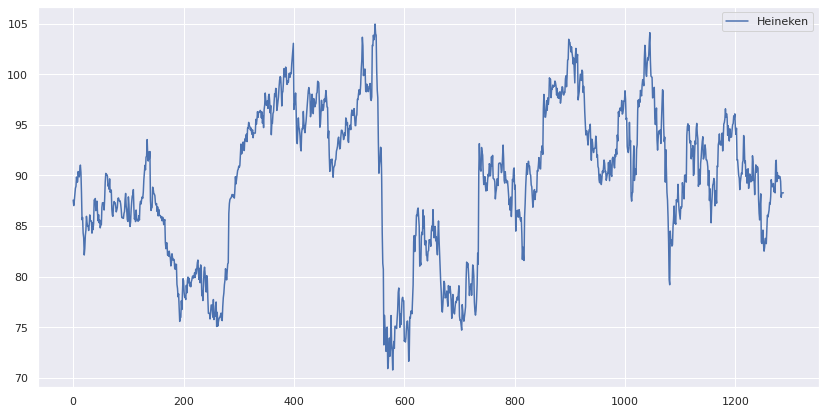

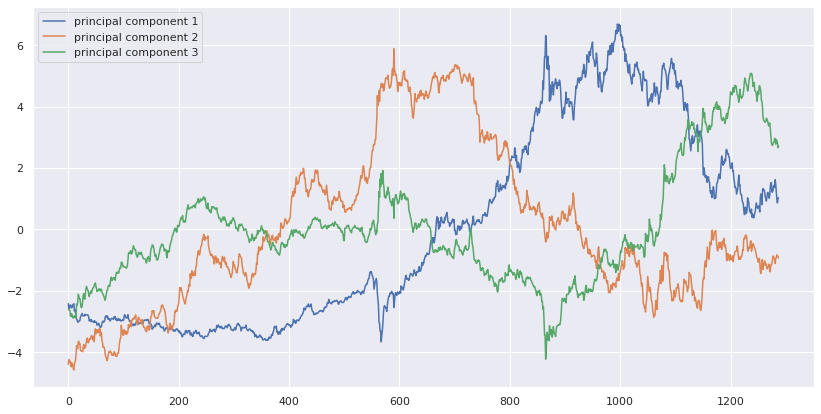

In [62]:
scale_function = lambda x: (x - x.mean())/x.std()
get_we = lambda x: x / x.sum()

share = portfolio_final.columns[16]

senp = portfolio_final.pop(share)

pca = PCA(n_components=3)

principalComponents = pca.fit_transform(portfolio_final.apply(scale_function))

principalDf = pd.DataFrame(data = principalComponents
            , columns = ['principal component 1', 'principal component 2', 'principal component 3'])



senp = senp.reset_index().drop('Date', axis = 1)

finalDf = principalDf.join(senp)

finalDf

X = finalDf.drop(share, axis = 1)
y = finalDf.loc[:, share]
X = sm.add_constant(X)

reg = sm.OLS(y, X).fit()



finalDf['Voorspelde waarde'] = reg.predict(X)

print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))
print(reg.summary())
print(senp.plot())
print(principalDf.plot())


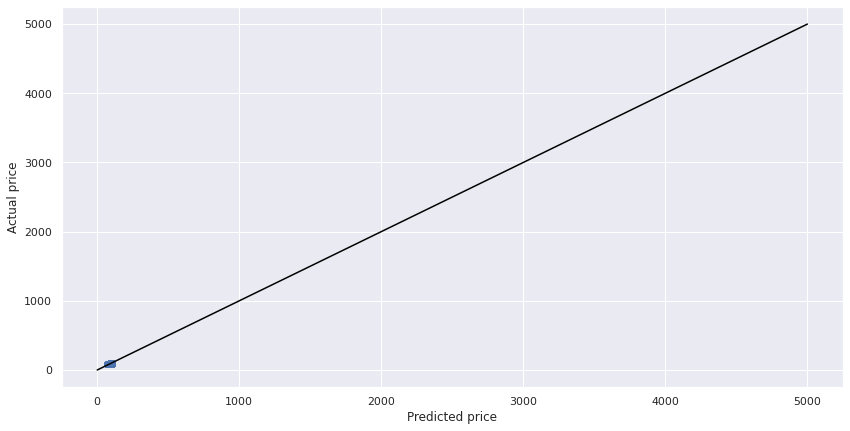

In [63]:
plt.scatter(finalDf[[share]], finalDf[['Voorspelde waarde']])
plt.ylabel('Actual price')
plt.xlabel('Predicted price')
plt.plot([0, 5000], [0, 5000], 'black') #1 to 1 line
plt.show()

In [64]:
X = portfolio_final.drop(portfolio_final.columns[17], axis = 1)

y = pd.cut(x= portfolio_final[portfolio_final.columns[17]], bins = [0, 4, 8, 12, 16, 20, 24],
                   labels = ['0-4', '4-8', '8-12', '12-16', '16,20', '20-24'])

Nbins = 10
labels = []
for i in range(Nbins):
  labels.append(int(i))

y = pd.cut(x= portfolio_final[portfolio_final.columns[17]], bins = Nbins,
           labels = labels)




X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

pca = PCA(n_components = 3)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

classifier = RandomForestClassifier(max_depth=2, random_state=0)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print(cm)
print('Accuracy :' + str(accuracy_score(y_test, y_pred)))


[[49  0  0  0  0  0  0  0  0  0]
 [17  0  6  0  0  0  0  0  0  0]
 [ 0  0 39  0  0  0  0  0  0  0]
 [ 0  0 15  0  0  0  0  0  0  0]
 [ 0  0  1  0 18  0  0  0  0  0]
 [ 0  0  0  0  8  7 12  0  0  0]
 [ 0  0  0  0  0  0 33  0  0  0]
 [ 0  0  0  0  0  0 24  2  0  0]
 [ 0  0  0  0  0  0 16  0  0  0]
 [ 0  0  0  0  0  0 11  0  0  0]]
Accuracy :0.5736434108527132


# Detrending

In [65]:
value = portfolio_final['ING']

Linear detrending

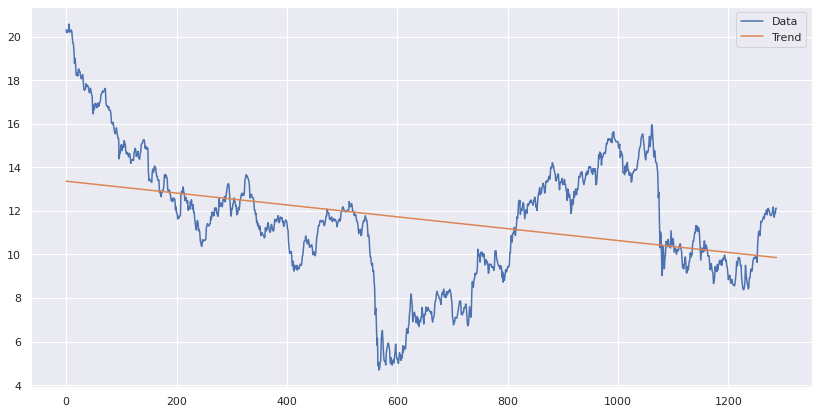

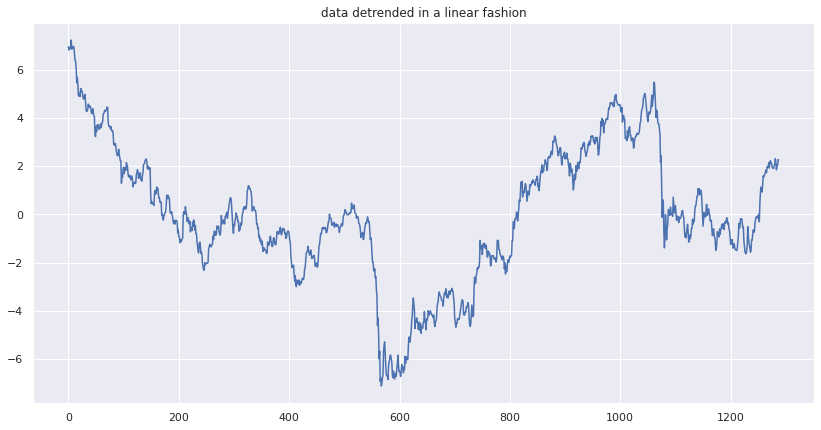

r2: 0.11726899574665905
rmse 2.7775215527734


In [74]:
X = value.reset_index().index
X = np.reshape(X, (len(X), 1))
y = value.values

model = LinearRegression()
model.fit(X,y)
trend = model.predict(X)

plt.plot(y)
plt.plot(trend)
plt.legend(['Data', 'Trend'])
plt.show()

detr = [y[i] - trend[i] for i in range(0, len(y))]
plt.plot(detr)
plt.title('data detrended in a linear fashion')
plt.show()

r2 = r2_score(y, trend)
rmse = np.sqrt(mean_squared_error(y, trend))
print('r2:', r2)
print('rmse', rmse)

Polynomial trend

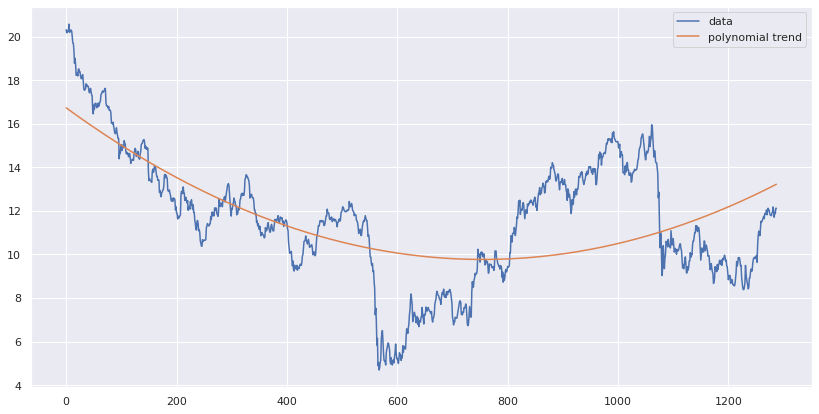

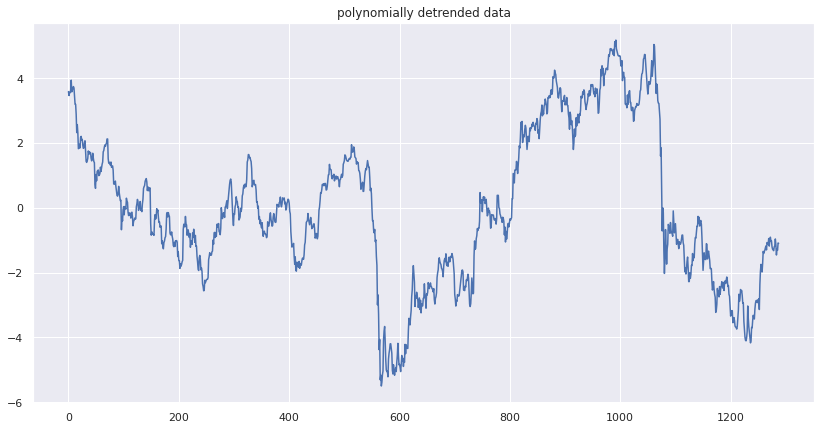

r2: 0.3774688870785943
rmse 2.332511416463319


In [67]:
pf = PolynomialFeatures(degree=2)
Xp = pf.fit_transform(X)

md2 = LinearRegression()
md2.fit(Xp, y)
trendp = md2.predict(Xp)

plt.plot(X, y)
plt.plot(X, trendp)
plt.legend(['data', 'polynomial trend'])
plt.show()

detrpoly = [y[i] - trendp[i] for i in range(0, len(y))]
plt.plot(X, detrpoly)
plt.title('polynomially detrended data')
plt.show()

r2 = r2_score(y, trendp)
rmse = np.sqrt(mean_squared_error(y, trendp))
print('r2:', r2)
print('rmse', rmse)


Logaritmic detrending

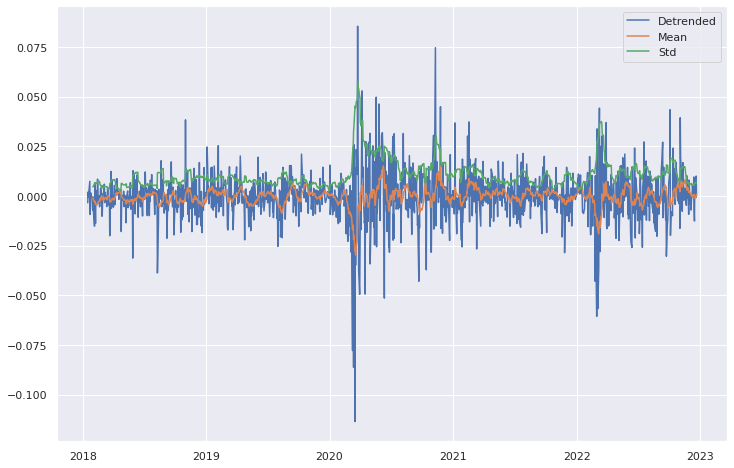

In [68]:
df_log = np.log(value)

df_log_ma= df_log.rolling(2).mean()
df_detrend = df_log - df_log_ma
df_detrend.dropna(inplace=True)

df_detrend_rolling = df_detrend.rolling(12)
df_detrend_ma = df_detrend_rolling.mean()
df_detrend_std = df_detrend_rolling.std()

plt.figure(figsize=(12, 8))
plt.plot(df_detrend, label='Detrended')
plt.plot(df_detrend_ma, label='Mean')
plt.plot(df_detrend_std, label='Std')
plt.legend(loc='upper right');

In [69]:
result = adfuller(df_detrend)
print('ADF statistic: ',  result[0])
print('p-value:  ', result[1])

critical_values = result[4]
for key, value in critical_values.items():
    print('Critical value (%s): %.3f' % (key, value))


ADF statistic:  -14.921938832251241
p-value:   1.4073389233857455e-27
Critical value (1%): -3.435
Critical value (5%): -2.864
Critical value (10%): -2.568


# Share used for Arima, Sarimax and Forecasting

In [70]:
value = portfolio_final['ING']

# ARIMA & SARIMAX

<function matplotlib.pyplot.show(*args, **kw)>

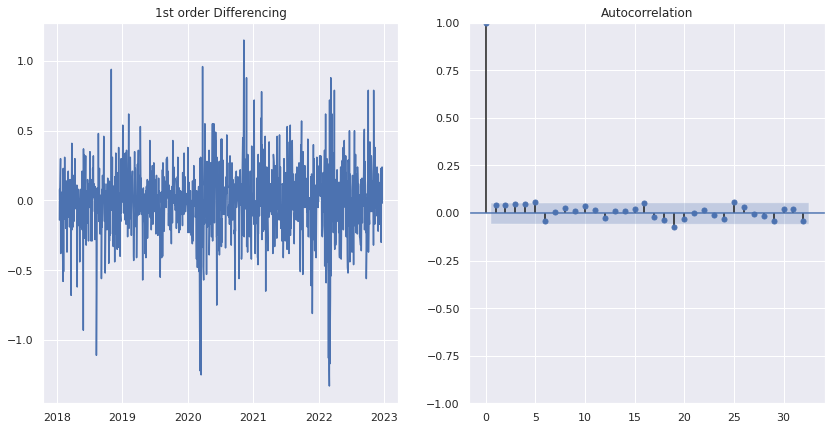

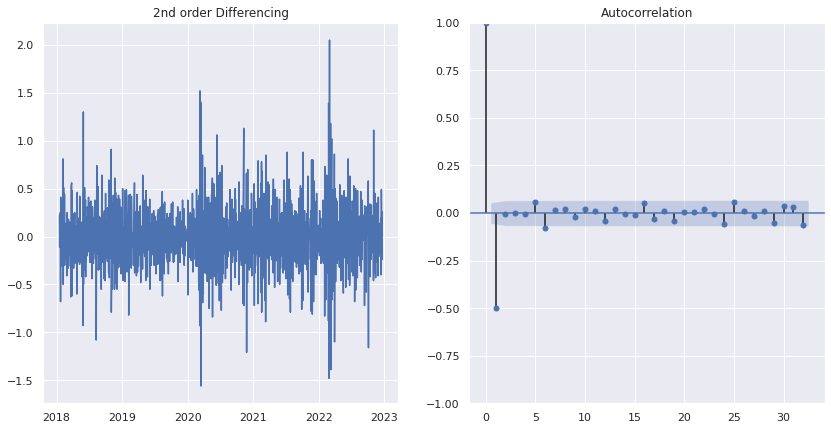

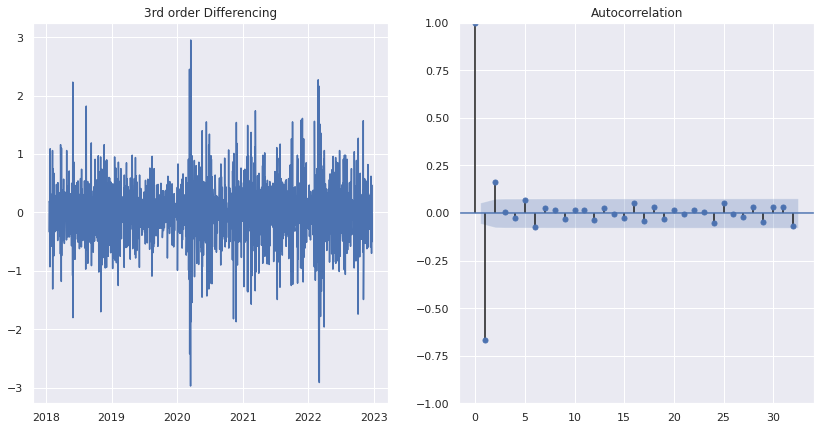

In [71]:
#1st order diffencing

f = plt.figure()
ax1 = f.add_subplot(121)
ax1.set_title('1st order Differencing')
ax1.plot(value.diff())

ax2 = f.add_subplot(122)
plot_acf(value.diff().dropna(), ax = ax2)
plt.show

#2nd order differencing

f = plt.figure()
ax1 = f.add_subplot(121)
ax1.set_title('2nd order Differencing')
ax1.plot(value.diff().diff())

ax2 = f.add_subplot(122)
plot_acf(value.diff().diff().dropna(), ax = ax2)
plt.show

#3rd order differencing

f = plt.figure()
ax1 = f.add_subplot(121)
ax1.set_title('3rd order Differencing')
ax1.plot(value.diff().diff().diff())

ax2 = f.add_subplot(122)
plot_acf(value.diff().diff().diff().dropna(), ax = ax2)
plt.show

In [72]:
result = adfuller(value.dropna())
print('ADF statistic: ',  result[0])
print('p-value:  ', result[1])

result = adfuller(value.diff().dropna())
print('ADF statistic: ',  result[0])
print('p-value:  ', result[1])

result = adfuller(value.diff().diff().dropna())
print('ADF statistic: ',  result[0])
print('p-value:  ', result[1])

ADF statistic:  -3.0140317790176545
p-value:   0.033604625188804416
ADF statistic:  -13.637953002221781
p-value:   1.674288273297972e-25
ADF statistic:  -12.250851346342005
p-value:   9.548125616557029e-23


In [73]:
arima_model = ARIMA(value, order = (0, 1, 3))
model = arima_model.fit(maxiter = 200, disp = False)
print(model.summary())

model.plot_predict(dynamic = False)
plt.show()

NotImplementedError: ignored

In [ ]:
y_pred = pd.Series(model.forecast(len(value)-1100)[0], index = value[1100:].index)
y_true = value[1100:]

mape = np.mean(np.abs(y_pred - y_true)/np.abs(y_true)) #Mean Absolute Percentage Error
mae = np.mean(np.abs(y_pred - y_true))         #Mean Absolute Error
mpe = np.mean((y_pred - y_true)/y_true)        #Mean Percentgae Error
rmse = np.mean((y_pred - y_true)**2)**5        #RMSE
corr = np.corrcoef(y_pred, y_true)[0, 1]       #Correlation Coefficient

mins = np.amin(np.hstack([y_pred[:,None], y_true[:,None]]), axis = 1)
maxs = np.amax(np.hstack([y_pred[:,None], y_true[:,None]]), axis = 1)
minmax = 1 - np.mean(mins/maxs)

pprint.pprint({'mape' : mape, 'mae': mae,
               'mpe' : mpe, 'rmse' : rmse,
               'corr' : corr, 'minmax' : minmax})



In [ ]:
def arima_grid_search(dataframe, s):
        p = d = q = range(2)
        param_combinations = list(itertools.product(p, d, q))
        lowest_aic, pdq, pdqs = None, None, None
        total_iterations = 0
        for order in param_combinations:    
            for (p, q, d) in param_combinations:
                seasonal_order = (p, q, d, s)
                total_iterations += 1
                try:
                    model = SARIMAX(dataframe, order=order, 
                        seasonal_order=seasonal_order, 
                        enforce_stationarity=False,
                        enforce_invertibility=False,
                        disp=False
                    )
                    model_result = model.fit(maxiter=200, disp=False)

                    if not lowest_aic or model_result.aic < lowest_aic:
                        lowest_aic = model_result.aic
                        pdq, pdqs = order, seasonal_order

                except Exception as ex:
                    continue

        return lowest_aic, pdq, pdqs, model

In [ ]:
lowest_aic, order, seasonal_order, model = arima_grid_search(value, 12)
print('ARIMA{}x{}'.format(order, seasonal_order))
print('Lowest AIC: %.3f'%lowest_aic)

In [ ]:
model_results = model.fit()
print(model_results.summary())

In [ ]:
model_results.plot_diagnostics(figsize=(12, 8));

In [ ]:
n = len(value.index)

prediction = model_results.get_prediction(
        start=n-1000, 
        end=n+5
    )
prediction_ci = prediction.conf_int()

plt.figure(figsize=(12, 6))

ax = value.plot(label='actual')
prediction_ci.plot(
        ax=ax, style=['--', '--'],
        label='predicted/forecasted')

ci_index = prediction_ci.index
lower_ci = prediction_ci.iloc[:, 0]
upper_ci = prediction_ci.iloc[:, 1]

ax.fill_between(ci_index, lower_ci, upper_ci,
        color='r', alpha=.1)

ax.set_xlabel('Time (years)')
ax.set_ylabel('Prices')

plt.legend()

# Forecaster

In [ ]:
f = Forecaster(y = value, current_dates = value.index)
f.generate_future_dates(12)
f.set_test_length(0.2)
f.set_estimator('arima')
f.manual_forecast(call_me = 'arima1')

f.plot_test_set(ci=True)
plt.title('ARIMA Test-Set Performandce', size = 14)
plt.show()

In [ ]:
f.plot_acf()
plt.show()
f.plot_pacf()
plt.show()
f.seasonal_decompose().plot()
plt.show()
stat, pval, _, _, _, _ = f.adf_test(full_res = True)
print(stat)
print(pval)

# Forecast
f.manual_forecast(order=(1,1,1),seasonal_order=(1,1,1,12),call_me='arima2')

# View test results
f.plot_test_set(ci=True,models='arima2')
plt.title('ARIMA Test-Set Performance',size=14)
plt.show()

# View forecast results
f.plot(ci=True,models='arima2')
plt.title('ARIMA Forecast Performance',size=14)
plt.show()

# See summary stats
f.regr.summary()

In [ ]:
auto_arima(
    f,
    start_P=1,
    start_q=1,
    max_p=6,
    max_q=6,
    m=12,
    seasonal=True,
    max_P=2, 
    max_D=2,
    max_Q=2,
    max_d=2,
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True,
    information_criterion="aic",
    alpha=0.05,
    scoring='mse',
    call_me='arima3',
)

f.plot_test_set(ci=True,models='arima3')
plt.title('ARIMA Test-Set Performance',size=14)
plt.show()

f.plot(ci=True,models='arima3')
plt.title('ARIMA Forecast Performance',size=14)
plt.show()

In [ ]:
f.set_validation_length(12)
grid = {
    'order':[(1,1,1),(1,1,0),(0,1,1)],
    'seasonal_order':[(2,1,1,12),(1,1,1,12),(2,1,0,12),(0,1,0,12)]
}

f.ingest_grid(grid)
f.tune()
f.auto_forecast(call_me='arima4')

f.plot_test_set(ci=True,models='arima4')
plt.title('ARIMA Test-Set Performance',size=14)
plt.show()

f.plot(ci=True,models='arima4')
plt.title('ARIMA Forecast Performance',size=14)
plt.show()

f.regr.summary()